# Positional Homophonic Cipher of the Voynich Manuscript

## Motivation

The compositional decipherment suffers from **degeneration**: the LM dominates the optimisation (`w_lm=2.0` vs `w_pos=0.5`) and 17 glyphs collapse onto shin. The *constrained* notebook reduced the maximum glyphs/char to 11 but worsened n-grams (24% → 5%).

Neither exploits the prediction of the **SilPart** model (best generative, d=0.445): **each consonant has graphic variants depending on its syllabic position** (onset vs coda), like the positional forms of Arabic.

**Core idea**: Impose that glyphs sharing syllabic position (both onset-specialists or both coda-specialists) must NOT map to the same character. Conversely, an onset-specialist and a coda-specialist CAN (they are positional variants of the same consonant). This is a **positional homophonic cipher**.

---
**Target language**: Hebrew (top Bayesian candidate)


In [11]:
# ── Cell 1: Imports ──────────────────────────────────────────────────
import re, json, math, time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from collections import Counter, defaultdict
from itertools import combinations
from scipy.spatial.distance import jensenshannon
from tqdm import tqdm

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
print('Imports OK')


Imports OK


In [12]:
# ── Cell 2: Reused functions ───────────────────────────────────
# Origin: compositional (Cells 2-4), constrained (Cells 5,7), validation (Cells 5,7,9)

STA_PATH = 'corpus/voynich_sta.txt'

# ═══════════════════════════════════════════════════════════════
# 1. Parsing and segmentation (compositional Cell 2)
# ═══════════════════════════════════════════════════════════════

def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def construir_matriz_transicion_intrapalabra(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M_raw = np.zeros((n, n))
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            r, c = index[palabra[i]], index[palabra[i + 1]]
            M_raw[r, c] += 1
    row_sums = M_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M_prob = M_raw / row_sums
    return M_raw, M_prob, all_glyphs, index


def segmentar_silabas_tp(palabras, M_prob, tokens_tr, index_tr, threshold_percentile=20):
    all_trans_probs = []
    for palabra in palabras:
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            if g1 in index_tr and g2 in index_tr:
                all_trans_probs.append(M_prob[index_tr[g1], index_tr[g2]])
    threshold_val = np.percentile(all_trans_probs, threshold_percentile)
    silabas_por_palabra = []
    for palabra in palabras:
        if len(palabra) == 0:
            continue
        syl = [palabra[0]]
        for i in range(len(palabra) - 1):
            g1, g2 = palabra[i], palabra[i + 1]
            p = M_prob[index_tr[g1], index_tr[g2]] if (g1 in index_tr and g2 in index_tr) else 0.0
            if p < threshold_val:
                silabas_por_palabra.append(tuple(syl))
                syl = [g2]
            else:
                syl.append(g2)
        if syl:
            silabas_por_palabra.append(tuple(syl))
        silabas_por_palabra.append(None)
    return silabas_por_palabra, all_trans_probs, threshold_val


def syls_to_words(syls_flat):
    words, current = [], []
    for item in syls_flat:
        if item is None:
            if current:
                words.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words.append(current)
    return words


def catalogar_silabas(silabas_por_palabra):
    syl_freq = Counter()
    syl_per_word = []
    syl_lengths = Counter()
    count_in_word = 0
    for item in silabas_por_palabra:
        if item is None:
            if count_in_word > 0:
                syl_per_word.append(count_in_word)
            count_in_word = 0
        else:
            syl_freq[item] += 1
            syl_lengths[len(item)] += 1
            count_in_word += 1
    if count_in_word > 0:
        syl_per_word.append(count_in_word)
    return syl_freq, syl_per_word, syl_lengths


def clasificar_silabas_posicionalmente(silabas_por_palabra, min_freq=5):
    words_as_syls = []
    current = []
    for item in silabas_por_palabra:
        if item is None:
            if current:
                words_as_syls.append(current)
            current = []
        else:
            current.append(item)
    if current:
        words_as_syls.append(current)
    pos_counts = defaultdict(lambda: {'inicio': 0, 'medio': 0, 'final': 0, 'total': 0})
    for word_syls in words_as_syls:
        n = len(word_syls)
        for i, syl in enumerate(word_syls):
            pos_counts[syl]['total'] += 1
            if n == 1:
                pos_counts[syl]['inicio'] += 1
                pos_counts[syl]['final'] += 1
            elif i == 0:
                pos_counts[syl]['inicio'] += 1
            elif i == n - 1:
                pos_counts[syl]['final'] += 1
            else:
                pos_counts[syl]['medio'] += 1
    clase_silaba = {}
    stats = {}
    for syl, counts in pos_counts.items():
        if counts['total'] < min_freq:
            continue
        total = counts['total']
        r_ini = counts['inicio'] / total
        r_fin = counts['final'] / total
        r_med = counts['medio'] / total
        if r_ini >= 0.60 and r_fin < 0.30:
            clase = 'onset'
        elif r_fin >= 0.60 and r_ini < 0.30:
            clase = 'coda'
        elif r_med >= 0.40:
            clase = 'nuclear'
        else:
            clase = 'free'
        clase_silaba[syl] = clase
        stats[syl] = {'clase': clase, 'inicio': r_ini, 'medio': r_med,
                       'final': r_fin, 'total': total}
    return clase_silaba, stats


def clasificar_glifos(palabras, WORDS_SYL_V, clase_silaba_v, VOCAB):
    """Classifies glyphs by their positional role within classified syllables."""
    glyph_in_class = defaultdict(Counter)
    glyph_position = defaultdict(Counter)
    for word_syls in WORDS_SYL_V:
        for syl in word_syls:
            clase = clase_silaba_v.get(syl, 'free')
            for i, g in enumerate(syl):
                glyph_in_class[g][clase] += 1
                if i == 0:
                    glyph_position[g]['inicio'] += 1
                elif i == len(syl) - 1:
                    glyph_position[g]['fin'] += 1
                else:
                    glyph_position[g]['medio'] += 1
    glyph_role = {}
    glyph_stats = {}
    for g in VOCAB:
        counts = glyph_in_class[g]
        total = sum(counts.values())
        if total < 5:
            glyph_role[g] = '?'
            glyph_stats[g] = {'role': '?', 'total': total, 'pct_nuclear': 0}
            continue
        pct_nuclear = counts.get('nuclear', 0) / total
        pct_onset = counts.get('onset', 0) / total
        pct_coda = counts.get('coda', 0) / total
        glyph_role[g] = 'V' if pct_nuclear > 0.40 else 'C'
        glyph_stats[g] = {
            'role': glyph_role[g], 'total': total,
            'pct_nuclear': pct_nuclear, 'pct_onset': pct_onset,
            'pct_coda': pct_coda, 'pct_free': counts.get('free', 0) / total,
            'pos_inicio': glyph_position[g].get('inicio', 0),
            'pos_medio': glyph_position[g].get('medio', 0),
            'pos_fin': glyph_position[g].get('fin', 0),
        }
    return glyph_role, glyph_stats


# ═══════════════════════════════════════════════════════════════
# 2. Hebrew download (compositional Cell 2)
# ═══════════════════════════════════════════════════════════════

def descargar_hebreo():
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        for capitulo in data['text']:
            for versiculo in capitulo:
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                pals = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in pals:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras


# ═══════════════════════════════════════════════════════════════
# 3. CharLM (compositional Cell 4)
# ═══════════════════════════════════════════════════════════════

class CharLM:
    """Character-level trigram LM with Witten-Bell smoothing."""

    def __init__(self, order=3):
        self.order = order
        self.trigram_counts = defaultdict(Counter)
        self.bigram_counts = defaultdict(Counter)
        self.unigram_counts = Counter()
        self.vocab = set()
        self.total = 0
        self._V = 0

    def fit(self, words):
        BOS = '<w>'
        EOS = '</w>'
        for word in words:
            seq = [BOS, BOS] + list(word) + [EOS]
            for c in seq:
                self.vocab.add(c)
                self.unigram_counts[c] += 1
                self.total += 1
            for i in range(len(seq) - 1):
                self.bigram_counts[seq[i]][seq[i+1]] += 1
            for i in range(len(seq) - 2):
                ctx = (seq[i], seq[i+1])
                self.trigram_counts[ctx][seq[i+2]] += 1
        self._V = len(self.vocab)

    def _log_prob_trigram(self, c1, c2, c3):
        ctx = (c1, c2)
        tri_counts = self.trigram_counts[ctx]
        tri_total = sum(tri_counts.values())
        if tri_total > 0:
            tri_seen = len(tri_counts)
            count = tri_counts.get(c3, 0)
            if count > 0:
                prob = count / (tri_total + tri_seen)
                return math.log2(max(prob, 1e-20))
            else:
                lambda_bo = tri_seen / (tri_total + tri_seen)
                bi_counts = self.bigram_counts[c2]
                bi_total = sum(bi_counts.values())
                if bi_total > 0:
                    bi_seen = len(bi_counts)
                    bi_count = bi_counts.get(c3, 0)
                    if bi_count > 0:
                        prob = lambda_bo * bi_count / (bi_total + bi_seen)
                    else:
                        lambda_bo2 = bi_seen / (bi_total + bi_seen)
                        prob = lambda_bo * lambda_bo2 * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                else:
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
        else:
            bi_counts = self.bigram_counts[c2]
            bi_total = sum(bi_counts.values())
            if bi_total > 0:
                bi_seen = len(bi_counts)
                count = bi_counts.get(c3, 0)
                if count > 0:
                    prob = count / (bi_total + bi_seen)
                else:
                    lambda_bo = bi_seen / (bi_total + bi_seen)
                    prob = lambda_bo * (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))
            else:
                prob = (self.unigram_counts.get(c3, 0) + 1) / (self.total + self._V)
                return math.log2(max(prob, 1e-20))

    def log_prob(self, word):
        BOS = '<w>'
        EOS = '</w>'
        seq = [BOS, BOS] + list(word) + [EOS]
        lp = 0.0
        for i in range(2, len(seq)):
            lp += self._log_prob_trigram(seq[i-2], seq[i-1], seq[i])
        return lp

    def perplexity(self, words):
        total_lp = 0.0
        total_n = 0
        for word in words:
            total_lp += self.log_prob(word)
            total_n += len(word) + 1
        if total_n == 0:
            return float('inf')
        return 2.0 ** (-total_lp / total_n)


# ═══════════════════════════════════════════════════════════════
# 4. Scoring functions (compositional Cell 4, constrained Cell 7)
# ═══════════════════════════════════════════════════════════════

def score_positional(mapping, glyph_role, char_role):
    n_ok = sum(1 for g, c in mapping.mapping.items()
               if glyph_role.get(g, '?') == char_role.get(c, '?')
               and glyph_role.get(g) != '?')
    n_total = sum(1 for g in mapping.mapping if glyph_role.get(g) != '?')
    return n_ok / max(n_total, 1)


def score_char_lm(mapping, words, char_lm, sample_size=3000):
    rng = np.random.default_rng(0)
    if len(palabras) > sample_size:
        idx = rng.choice(len(palabras), size=sample_size, replace=False)
        sample = [words[i] for i in idx]
    else:
        sample = words
    mapped = [mapping.apply_word(w) for w in sample]
    return np.mean([char_lm.log_prob(w) for w in mapped])


def score_entropy(mapping_state):
    char_counts = Counter(mapping_state.mapping.values())
    if len(char_counts) <= 1:
        return 0.0
    total = sum(char_counts.values())
    probs = np.array([c / total for c in char_counts.values()])
    probs = probs[probs > 0]
    H = -np.sum(probs * np.log2(probs))
    H_max = np.log2(len(char_counts))
    if H_max < 1e-10:
        return 0.0
    return H / H_max


def score_grammar(mapping_state, glyph_anchor_sets):
    if not glyph_anchor_sets:
        return 0.0
    n_anchored = 0
    score = 0.0
    for g, anchor_set in glyph_anchor_sets.items():
        if not anchor_set:
            continue
        n_anchored += 1
        mapped_char = mapping_state.mapping.get(g)
        if mapped_char in anchor_set:
            score += 1.0
        else:
            score -= 1.0
    if n_anchored == 0:
        return 0.0
    return score / n_anchored


def score_total_comp_fast(mapping, words_sample, char_lm, glyph_role, char_role,
                          w_lm=2.0, w_pos=0.5):
    mapped = [mapping.apply_word(w) for w in words_sample]
    s_lm = np.mean([char_lm.log_prob(w) for w in mapped])
    s_pos = score_positional(mapping, glyph_role, char_role)
    return w_lm * s_lm + w_pos * s_pos


# ═══════════════════════════════════════════════════════════════
# 5. Grammar anchors (constrained Cell 5)
# ═══════════════════════════════════════════════════════════════

HEBREW_PREFIXES = set('והבכלמש')
HEBREW_SUFFIXES = set('התםןך')
HEBREW_ROOT_CONSONANTS = set('אבגדהוזחטיכלמנסעפצקרשת') - HEBREW_PREFIXES - HEBREW_SUFFIXES

GRAMMAR_ANCHORS = {
    'D1': HEBREW_PREFIXES,
    'K1': HEBREW_PREFIXES | {'ש'},
    'L1': {'ל', 'ה', 'ב', 'מ'},
    'Q1': HEBREW_ROOT_CONSONANTS,
    'Q2': HEBREW_ROOT_CONSONANTS,
    'A2': HEBREW_SUFFIXES,
    'C1': HEBREW_SUFFIXES,
}


def build_glyph_grammar_roles(palabras, glyph_stats, VOCAB):
    glyph_grammar_role = {}
    direct_rules = {
        'D1': 'prefix', 'K1': 'classifier', 'L1': 'prefix',
        'Q1': 'root', 'Q2': 'root',
        'A2': 'suffix', 'C1': 'suffix',
    }
    for g in VOCAB:
        if g in direct_rules:
            glyph_grammar_role[g] = direct_rules[g]
            continue
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        if total < 10:
            continue
        pos_ini = s.get('pos_inicio', 0)
        pos_fin = s.get('pos_fin', 0)
        pos_med = s.get('pos_medio', 0)
        pos_total = pos_ini + pos_fin + pos_med
        if pos_total == 0:
            continue
        r_ini = pos_ini / pos_total
        r_fin = pos_fin / pos_total
        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)
        pct_nuclear = s.get('pct_nuclear', 0)
        if pct_onset > 0.50 and r_ini > 0.50:
            glyph_grammar_role[g] = 'prefix'
        elif pct_coda > 0.50 and r_fin > 0.50:
            glyph_grammar_role[g] = 'suffix'
        elif pct_nuclear > 0.40:
            glyph_grammar_role[g] = 'root'
    role_to_anchor = {
        'prefix': HEBREW_PREFIXES,
        'classifier': HEBREW_PREFIXES | {'ש'},
        'root': HEBREW_ROOT_CONSONANTS,
        'suffix': HEBREW_SUFFIXES,
    }
    glyph_anchor_sets = {}
    for g, role in glyph_grammar_role.items():
        glyph_anchor_sets[g] = role_to_anchor.get(role, set())
    return glyph_grammar_role, glyph_anchor_sets


# ═══════════════════════════════════════════════════════════════
# 6. GlyphMappingState (compositional Cell 4)
# ═══════════════════════════════════════════════════════════════

class GlyphMappingState:
    def __init__(self, voynich_glyphs, target_chars, glyph_role=None, char_role=None):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = GlyphMappingState(self.voynich_glyphs, self.target_chars,
                                self.glyph_role, self.char_role)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars
        new.mapping[glyph] = rng.choice(candidates)
        return new

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


# ═══════════════════════════════════════════════════════════════
# 7. Init + EM + MCMC (compositional Cell 4, constrained Cell 2)
# ═══════════════════════════════════════════════════════════════

def init_frequency_mapping(palabras, vocab_glyphs, target_chars, target_words,
                           glyph_role, char_role):
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)
    mapping = {}
    for role in ('C', 'V', '?'):
        glyphs_r = sorted([g for g in vocab_glyphs if glyph_role.get(g, '?') == role],
                          key=lambda g: gf[g], reverse=True)
        if role == '?':
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        else:
            chars_r = sorted([c for c in target_chars if char_role.get(c) == role],
                             key=lambda c: cf.get(c, 0), reverse=True)
        if not chars_r:
            chars_r = sorted(target_chars, key=lambda c: cf.get(c, 0), reverse=True)
        for i, g in enumerate(glyphs_r):
            mapping[g] = chars_r[i % len(chars_r)]
    return mapping


def mcmc_glyph_refine(initial_state, words, char_lm, glyph_role, char_role,
                      n_iter=15000, T_start=1.0, T_end=0.01, seed=42,
                      sample_size=3000, thin=5,
                      adaptive=True, target_accept=0.35,
                      calibration_samples=300, T_ratio=100,
                      w_lm=2.0, w_pos=0.5,
                      score_fn=None, score_fn_kwargs=None):
    """MCMC Metropolis-Hastings with adaptive annealing."""
    rng = np.random.default_rng(seed)
    if len(palabras) > sample_size:
        idx = rng.choice(len(palabras), size=sample_size, replace=False)
        words_sample = [words[i] for i in idx]
    else:
        words_sample = words

    if score_fn is None:
        def _score(state):
            return score_total_comp_fast(state, words_sample, char_lm,
                                         glyph_role, char_role,
                                         w_lm=w_lm, w_pos=w_pos)
    else:
        _kw = score_fn_kwargs or {}
        def _score(state):
            return score_fn(state, words_sample, char_lm, glyph_role, char_role, **_kw)

    current = initial_state
    current_score = _score(current)

    if adaptive:
        neg_deltas = []
        cal_state = current
        cal_score = current_score
        for _ in range(calibration_samples):
            prop = cal_state.propose_change(rng, constrained=True)
            ps = _score(prop)
            d = ps - cal_score
            if d < 0:
                neg_deltas.append(abs(d))
            cal_state = prop
            cal_score = ps
        if neg_deltas:
            median_neg = float(np.median(neg_deltas))
            T_start = median_neg / (-math.log(target_accept))
            T_end = T_start / T_ratio
            print(f'    Adaptive T: median|delta|={median_neg:.4f} '
                  f'-> T_start={T_start:.6f}, T_end={T_end:.8f}')
        else:
            print(f'    Adaptive T: no negative deltas found, using defaults')

    best = current
    best_score = current_score
    chain_scores = [current_score]
    chain_mappings = [dict(current.mapping)]
    _thin_counter = 0
    temperatures = []
    accepted = 0

    for it in range(n_iter):
        T = T_start * (T_end / T_start) ** (it / max(n_iter - 1, 1))
        temperatures.append(T)
        proposal = current.propose_change(rng, constrained=True)
        prop_score = _score(proposal)
        delta = prop_score - current_score
        if delta > 0 or rng.random() < math.exp(delta / max(T, 1e-10)):
            current = proposal
            current_score = prop_score
            accepted += 1
            if current_score > best_score:
                best = current
                best_score = current_score
        chain_scores.append(current_score)
        _thin_counter += 1
        if _thin_counter % thin == 0:
            chain_mappings.append(dict(current.mapping))
        if (it + 1) % 3000 == 0:
            print(f'    MCMC iter {it+1}: score={current_score:.4f}, '
                  f'best={best_score:.4f}, T={T:.6f}, accept={accepted/(it+1):.1%}')

    accept_rate = accepted / n_iter
    return best, chain_scores, chain_mappings, temperatures, accept_rate


def mcmc_glyph_multi_chain(initial_state, words, char_lm, glyph_role, char_role,
                           n_chains=4, seeds=(42, 137, 256, 999),
                           n_iter=15000, burn_in=3000, thin=5,
                           adaptive=True, target_accept=0.35,
                           calibration_samples=300, T_ratio=100,
                           sample_size=3000, w_lm=2.0, w_pos=0.5,
                           score_fn=None, score_fn_kwargs=None):
    """Execute N independent MCMC chains."""
    chains = []
    global_best = None
    global_best_score = -np.inf
    for i in range(n_chains):
        seed = seeds[i] if i < len(seeds) else seeds[0] + i * 100
        print(f'  Chain {i+1}/{n_chains} (seed={seed})')
        best, scores, mappings, temps, accept = mcmc_glyph_refine(
            initial_state, words, char_lm, glyph_role, char_role,
            n_iter=n_iter, seed=seed, thin=thin,
            adaptive=adaptive, target_accept=target_accept,
            calibration_samples=calibration_samples, T_ratio=T_ratio,
            sample_size=sample_size, w_lm=w_lm, w_pos=w_pos,
            score_fn=score_fn, score_fn_kwargs=score_fn_kwargs)
        chain_data = {
            'seed': seed,
            'chain_scores': scores,
            'chain_mappings': mappings,
            'temperatures': temps,
            'accept_rate': accept,
            'best_state': best,
            'best_score': max(scores) if scores else -np.inf,
        }
        chains.append(chain_data)
        if chain_data['best_score'] > global_best_score:
            global_best_score = chain_data['best_score']
            global_best = best
    return {
        'best_state': global_best,
        'best_score': global_best_score,
        'chains': chains,
        'n_chains': n_chains,
        'seeds': list(seeds[:n_chains]),
        'n_iter': n_iter,
        'burn_in': burn_in,
        'thin': thin,
    }


def posterior_glyph_multi_chain(mcmc_result, burn_in=3000):
    chains = mcmc_result['chains']
    thin = mcmc_result.get('thin', 1)
    burn_idx = max(burn_in // thin, 1)
    all_post_burn = []
    for ch in chains:
        mappings = ch['chain_mappings']
        if len(mappings) > burn_idx:
            all_post_burn.extend(mappings[burn_idx:])
    if not all_post_burn:
        return {}, {}, 0
    counts = defaultdict(Counter)
    for mapping in all_post_burn:
        for g, c in mapping.items():
            counts[g][c] += 1
    n_total = len(all_post_burn)
    posterior = {}
    for g in counts:
        total = sum(counts[g].values())
        posterior[g] = {c: cnt / total for c, cnt in counts[g].items()}
    rhat = {}
    for g in counts:
        map_target = max(counts[g], key=counts[g].get)
        chain_means = []
        chain_ns = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if m.get(g) == map_target else 0.0 for m in post_burn]
            chain_means.append(np.mean(indicators))
            chain_ns.append(len(indicators))
        if len(chain_means) < 2:
            rhat[g] = float('nan')
            continue
        m_ch = len(chain_means)
        n_per = np.mean(chain_ns)
        grand_mean = np.mean(chain_means)
        B = n_per / (m_ch - 1) * sum((cm - grand_mean) ** 2 for cm in chain_means)
        W_terms = []
        for ch in chains:
            mappings = ch['chain_mappings']
            post_burn = mappings[burn_idx:] if len(mappings) > burn_idx else []
            if not post_burn:
                continue
            indicators = [1.0 if md.get(g) == map_target else 0.0 for md in post_burn]
            W_terms.append(np.var(indicators, ddof=1) if len(indicators) > 1 else 0.0)
        W = np.mean(W_terms)
        if W < 1e-12:
            rhat[g] = 1.0 if B < 1e-12 else float('inf')
        else:
            var_hat = (1 - 1 / n_per) * W + (1 / n_per) * B
            rhat[g] = math.sqrt(var_hat / W)
    return posterior, rhat, n_total


# ═══════════════════════════════════════════════════════════════
# 8. Validation (validation Cells 5, 7, 9)
# ═══════════════════════════════════════════════════════════════

def positional_distribution(glyph, palabras):
    counts = np.array([0.0, 0.0, 0.0])
    for word in palabras:
        for i, g in enumerate(word):
            if g == glyph:
                if len(word) == 1:
                    counts[0] += 0.5
                    counts[2] += 0.5
                elif i == 0:
                    counts[0] += 1
                elif i == len(word) - 1:
                    counts[2] += 1
                else:
                    counts[1] += 1
    total = counts.sum()
    if total == 0:
        return np.array([1/3, 1/3, 1/3])
    return counts / total


def collapse_coherence_test(mapping, palabras, n_shuffles=200, min_group_size=3):
    groups = defaultdict(list)
    for g, c in mapping.items():
        groups[c].append(g)
    all_glyphs = list(mapping.keys())
    pos_dists = {}
    for g in all_glyphs:
        pos_dists[g] = positional_distribution(g, palabras)
    results = {}
    for char, glyphs in groups.items():
        if len(glyphs) < min_group_size:
            continue
        pairs = list(combinations(glyphs, 2))
        if not pairs:
            continue
        real_jsds = []
        for g1, g2 in pairs:
            d1 = pos_dists[g1] + 1e-10
            d2 = pos_dists[g2] + 1e-10
            real_jsds.append(jensenshannon(d1, d2))
        real_mean_jsd = np.mean(real_jsds)
        rng = np.random.default_rng(42)
        null_jsds = []
        for _ in range(n_shuffles):
            random_group = rng.choice(all_glyphs, size=len(glyphs), replace=False)
            null_pairs = list(combinations(random_group, 2))
            jsds = [jensenshannon(pos_dists[g1] + 1e-10, pos_dists[g2] + 1e-10)
                    for g1, g2 in null_pairs]
            null_jsds.append(np.mean(jsds))
        null_mean = np.mean(null_jsds)
        null_std = np.std(null_jsds) if np.std(null_jsds) > 1e-10 else 1e-10
        z_score = (real_mean_jsd - null_mean) / null_std
        if z_score > 1.5:
            verdict = 'STRUCTURED'
        elif z_score < -1.5:
            verdict = 'DEGENERATE'
        else:
            verdict = 'AMBIGUOUS'
        results[char] = {
            'n_glyphs': len(glyphs),
            'glyphs': glyphs,
            'real_jsd': real_mean_jsd,
            'null_mean': null_mean,
            'null_std': null_std,
            'z_score': z_score,
            'verdict': verdict,
        }
    return results


def corpus_trigram_distribution(words):
    trigram_counts = Counter()
    total = 0
    BOS, EOS = '<w>', '</w>'
    for word in words:
        seq = [BOS, BOS] + list(word) + [EOS]
        for i in range(len(seq) - 2):
            tri = (seq[i], seq[i+1], seq[i+2])
            trigram_counts[tri] += 1
            total += 1
    if total == 0:
        return {}
    return {tri: cnt / total for tri, cnt in trigram_counts.items()}


def trigram_jsd(dist1, dist2):
    all_keys = set(dist1.keys()) | set(dist2.keys())
    p = np.array([dist1.get(k, 0) for k in all_keys])
    q = np.array([dist2.get(k, 0) for k in all_keys])
    p = p + 1e-12
    q = q + 1e-12
    p = p / p.sum()
    q = q / q.sum()
    return float(jensenshannon(p, q))


def ngram_realism_test(mapping_state, palabras, hebrew_words, n_shuffles=100,
                       sample_size=5000):
    rng = np.random.default_rng(42)
    heb_sample = hebrew_words[:sample_size] if len(hebrew_words) > sample_size else hebrew_words
    ref_dist = corpus_trigram_distribution(heb_sample)
    voynich_sample = palabras[:sample_size] if len(palabras) > sample_size else palabras
    mapped_real = [mapping_state.apply_word(w) for w in voynich_sample]
    real_dist = corpus_trigram_distribution(mapped_real)
    real_jsd = trigram_jsd(real_dist, ref_dist)
    real_types = len(set(''.join(w) for w in mapped_real))
    vals = np.array(list(real_dist.values()))
    vals = vals[vals > 0]
    real_entropy = -np.sum(vals * np.log2(vals))
    null_jsds = []
    null_entropies = []
    null_diversities = []
    all_chars = list(set(mapping_state.mapping.values()))
    for _ in tqdm(range(n_shuffles), desc='Null shuffles'):
        shuffled_mapping = {}
        for g in mapping_state.mapping:
            shuffled_mapping[g] = rng.choice(all_chars)
        shuf_state = GlyphMappingState(mapping_state.voynich_glyphs,
                                        mapping_state.target_chars,
                                        mapping_state.glyph_role,
                                        mapping_state.char_role)
        shuf_state.set_mapping(shuffled_mapping)
        mapped_shuf = [shuf_state.apply_word(w) for w in voynich_sample]
        shuf_dist = corpus_trigram_distribution(mapped_shuf)
        null_jsds.append(trigram_jsd(shuf_dist, ref_dist))
        vals_s = np.array(list(shuf_dist.values()))
        vals_s = vals_s[vals_s > 0]
        null_entropies.append(-np.sum(vals_s * np.log2(vals_s)))
        null_diversities.append(len(set(''.join(w) for w in mapped_shuf)))
    percentile_jsd = 100 * (1 - np.mean([real_jsd < nj for nj in null_jsds]))
    return {
        'real_jsd': real_jsd,
        'null_jsds': null_jsds,
        'percentile_jsd': percentile_jsd,
        'real_entropy': real_entropy,
        'null_entropies': null_entropies,
        'real_diversity': real_types,
        'null_diversities': null_diversities,
    }


HEBREW_CONSONANTS_SET = set('בגדהוזחטיכלמנסעפצקרשת') | set('ךםןףץ')
HEBREW_MATRES = set('אוי')

HEBREW_ROOTS = {
    'אמר', 'דבר', 'היה', 'בוא', 'עשה', 'נתן', 'ידע', 'הלך', 'ראה', 'שמע',
    'אכל', 'לקח', 'ישב', 'קרא', 'שלח', 'עלה', 'מות', 'שוב', 'ברך', 'יצא',
    'עבר', 'שמר', 'כתב', 'נשא', 'זכר', 'ילד', 'עמד', 'פנה', 'בנה', 'נפל',
    'שים', 'חיה', 'גדל', 'קום', 'מלא', 'מצא', 'שפט', 'אהב', 'ירד', 'נגד',
    'יסף', 'חטא', 'קדש', 'כהן', 'צוה', 'ברא', 'גלה', 'זבח', 'טהר', 'טמא',
    'ארץ', 'בית', 'שנה', 'יום', 'מים', 'שמש', 'ליל', 'אבן', 'עיר', 'דרך',
    'מלך', 'כסף', 'זהב', 'דמם', 'רוח', 'נפש', 'לחם', 'עין', 'ידד', 'שדה',
    'עבד', 'כלי', 'פרי', 'חדש', 'ספר', 'עצם', 'בשר', 'אדם', 'נהר', 'גבר',
    'רגל', 'ראש', 'חזק', 'רבב', 'קטן', 'טוב', 'רעע', 'חכם', 'צדק', 'רחם',
    'כול', 'בקר', 'צאן', 'עוף', 'דגג', 'שמן', 'יין', 'סוס', 'גמל', 'חמר',
}


def extract_skeleton(mapped_word, confidences, conf_threshold=0.70,
                     glyph_word=None):
    skeleton = []
    for i, char in enumerate(mapped_word):
        if char in HEBREW_MATRES:
            continue
        if char not in HEBREW_CONSONANTS_SET:
            continue
        if glyph_word and i < len(glyph_word):
            g = glyph_word[i]
            conf = confidences.get(g, 0)
            if conf < conf_threshold:
                skeleton.append('*')
            else:
                skeleton.append(char)
        else:
            skeleton.append(char)
    return ''.join(skeleton)


def match_skeleton_to_root(skeleton, root):
    if len(skeleton) != len(root):
        return False
    for s, r in zip(skeleton, root):
        if s == '*':
            continue
        if s != r:
            return False
    return True


def root_matching(palabras, mapping, confidences, hebrew_roots,
                  conf_threshold=0.70, top_n=200):
    word_freq = Counter()
    for w in palabras:
        word_freq[tuple(w)] += 1
    top_words = word_freq.most_common(top_n)
    matches = []
    skeletons_seen = Counter()
    roots_matched = set()
    for word_tuple, freq in top_words:
        word_glyphs = list(word_tuple)
        mapped = [mapping.get(g, '?') for g in word_glyphs]
        skeleton = extract_skeleton(mapped, confidences, conf_threshold, word_glyphs)
        if len(skeleton) < 3:
            continue
        for i in range(len(skeleton) - 2):
            sub = skeleton[i:i+3]
            skeletons_seen[sub] += 1
            for root in hebrew_roots:
                if match_skeleton_to_root(sub, root):
                    roots_matched.add(root)
                    matches.append({
                        'word': ''.join(word_glyphs),
                        'mapped': ''.join(mapped),
                        'skeleton': skeleton,
                        'sub_skeleton': sub,
                        'root': root,
                        'freq': freq,
                        'n_wildcards': sub.count('*'),
                    })
    n_roots = len(hebrew_roots)
    n_consonants = len(HEBREW_CONSONANTS_SET)
    unique_skeletons = len(skeletons_seen)
    n_wildcards_mean = np.mean([s.count('*') for s in skeletons_seen.keys()]) if skeletons_seen else 0
    expected_matches_per_skel = n_roots * (1 / n_consonants) ** max(3 - n_wildcards_mean, 0.5)
    expected_total = expected_matches_per_skel * unique_skeletons
    return {
        'matches': matches,
        'n_matches': len(matches),
        'n_distinct_roots': len(roots_matched),
        'roots_matched': roots_matched,
        'n_skeletons': unique_skeletons,
        'n_wildcards_mean': n_wildcards_mean,
        'expected_matches': expected_total,
        'enrichment': len(matches) / max(expected_total, 1),
    }


print('Reused functions loaded OK')


Reused functions loaded OK


In [13]:
# ── Cell 3: Load Voynich + glyph classification ─────────────────

tokens_voynich = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens_voynich)
VOCAB = sorted({g for p in palabras for g in p})

print(f'Voynich corpus: {len(palabras):,} words, {len(VOCAB)} distinct glyphs')

# Syllabic segmentation
M_raw, M_prob, all_glyphs, index_tr = construir_matriz_transicion_intrapalabra(palabras)
silabas_flat, _, thr = segmentar_silabas_tp(palabras, M_prob, all_glyphs, index_tr)
WORDS_SYL = syls_to_words(silabas_flat)

# Catalogue and classify syllables
syl_freq, syl_per_word, syl_lengths = catalogar_silabas(silabas_flat)
clase_silaba, syl_stats = clasificar_silabas_posicionalmente(silabas_flat)

# Classify glyphs
glyph_role, glyph_stats = clasificar_glifos(palabras, WORDS_SYL, clase_silaba, VOCAB)

n_C = sum(1 for g in VOCAB if glyph_role.get(g) == 'C')
n_V = sum(1 for g in VOCAB if glyph_role.get(g) == 'V')
n_unk = sum(1 for g in VOCAB if glyph_role.get(g) == '?')
print(f'Roles: C={n_C}, V={n_V}, ?={n_unk}')

# Show some examples
rows = []
for g in sorted(glyph_stats.keys(), key=lambda x: glyph_stats[x].get('total', 0), reverse=True)[:20]:
    s = glyph_stats[g]
    rows.append({
        'Glyph': g, 'Role': s['role'], 'Total': s['total'],
        'pct_onset': f"{s.get('pct_onset', 0):.0%}",
        'pct_coda': f"{s.get('pct_coda', 0):.0%}",
        'pct_nuclear': f"{s.get('pct_nuclear', 0):.0%}",
        'pct_free': f"{s.get('pct_free', 0):.0%}",
    })
pd.DataFrame(rows)


Voynich corpus: 37,087 words, 166 distinct glyphs
Roles: C=70, V=5, ?=91


,Glyph,Role,Total,pct_onset,pct_coda,pct_nuclear,pct_free
0,A1,C,25106,36%,1%,1%,62%
1,A2,C,17464,4%,43%,0%,53%
2,A3,C,14545,14%,2%,2%,83%
3,K1,C,11066,44%,3%,3%,50%
4,B2,C,10668,6%,3%,0%,90%
5,B1,C,10492,6%,23%,1%,70%
6,J1,C,10257,26%,5%,4%,65%
7,Q1,C,9935,29%,1%,7%,63%
8,C1,C,6770,3%,5%,1%,92%
9,Q2,C,6113,30%,0%,6%,64%


Positional groups (threshold=65%):
  Onset:    0 glyphs — ...
  Coda:    14 glyphs — Ab, B3, B4, E2, F3, G3, H1, M1, U1, U3...
  Mixed:   38 glyphs — A1, A2, A3, Aa, B1, B2, B5, Ba, C1, C2...
  Vowel:    5 glyphs — E1, F2, P2, Qa, Z1
  Rare:   109 glyphs


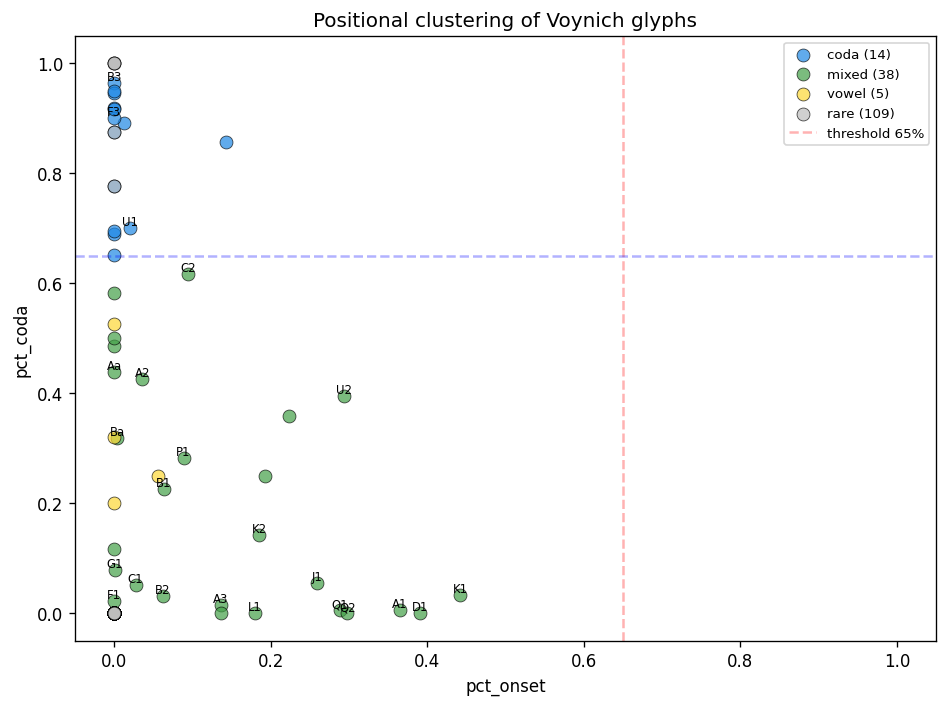

In [14]:
# ── Cell 4: Positional glyph clustering (NEW) ─────────────────

def classify_positional_group(glyph_stats, VOCAB, glyph_role,
                               onset_threshold=0.65, coda_threshold=0.65, min_freq=10):
    """Classify consonants into onset/coda/mixed according to pct_onset/pct_coda.

    Returns:
        pos_group: dict glyph -> 'onset'/'coda'/'mixed'/'vowel'/'rare'
        onset_glyphs, coda_glyphs, mixed_glyphs: lists
    """
    pos_group = {}
    onset_glyphs = []
    coda_glyphs = []
    mixed_glyphs = []

    for g in VOCAB:
        s = glyph_stats.get(g, {})
        total = s.get('total', 0)
        role = glyph_role.get(g, '?')

        if total < min_freq:
            pos_group[g] = 'rare'
            continue

        if role == 'V':
            pos_group[g] = 'vowel'
            continue

        if role == '?':
            pos_group[g] = 'rare'
            continue

        pct_onset = s.get('pct_onset', 0)
        pct_coda = s.get('pct_coda', 0)

        if pct_onset >= onset_threshold:
            pos_group[g] = 'onset'
            onset_glyphs.append(g)
        elif pct_coda >= coda_threshold:
            pos_group[g] = 'coda'
            coda_glyphs.append(g)
        else:
            pos_group[g] = 'mixed'
            mixed_glyphs.append(g)

    return pos_group, onset_glyphs, coda_glyphs, mixed_glyphs


# Execute classification with threshold=0.65
pos_group, onset_glyphs, coda_glyphs, mixed_glyphs = classify_positional_group(
    glyph_stats, VOCAB, glyph_role,
    onset_threshold=0.65, coda_threshold=0.65, min_freq=10)

# Summary
vowel_glyphs = [g for g in VOCAB if pos_group.get(g) == 'vowel']
rare_glyphs = [g for g in VOCAB if pos_group.get(g) == 'rare']

print(f'Positional groups (threshold=65%):')
print(f'  Onset:  {len(onset_glyphs):3d} glyphs — {", ".join(sorted(onset_glyphs)[:10])}...')
print(f'  Coda:   {len(coda_glyphs):3d} glyphs — {", ".join(sorted(coda_glyphs)[:10])}...')
print(f'  Mixed:  {len(mixed_glyphs):3d} glyphs — {", ".join(sorted(mixed_glyphs)[:10])}...')
print(f'  Vowel:  {len(vowel_glyphs):3d} glyphs — {", ".join(sorted(vowel_glyphs)[:10])}')
print(f'  Rare:   {len(rare_glyphs):3d} glyphs')

# Scatter plot: pct_onset vs pct_coda
fig, ax = plt.subplots(figsize=(8, 6))
colors_map = {'onset': '#E53935', 'coda': '#1E88E5', 'mixed': '#43A047',
              'vowel': '#FDD835', 'rare': '#BDBDBD'}

for group_name, color in colors_map.items():
    glyphs_g = [g for g in VOCAB if pos_group.get(g) == group_name]
    if not glyphs_g:
        continue
    x = [glyph_stats.get(g, {}).get('pct_onset', 0) for g in glyphs_g]
    y = [glyph_stats.get(g, {}).get('pct_coda', 0) for g in glyphs_g]
    ax.scatter(x, y, c=color, label=f'{group_name} ({len(glyphs_g)})',
               alpha=0.7, edgecolors='k', linewidth=0.5, s=60)
    # Annotate important glyphs
    for g, xi, yi in zip(glyphs_g, x, y):
        if glyph_stats.get(g, {}).get('total', 0) > 500:
            ax.annotate(g, (xi, yi), fontsize=7, ha='center', va='bottom')

ax.axvline(0.65, color='red', linestyle='--', alpha=0.3, label='threshold 65%')
ax.axhline(0.65, color='blue', linestyle='--', alpha=0.3)
ax.set_xlabel('pct_onset')
ax.set_ylabel('pct_coda')
ax.set_title('Positional clustering of Voynich glyphs')
ax.legend(loc='upper right', fontsize=8)
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()


## Positional group analysis

The scatter plot shows the separation between:
- **Onset-specialists** (red): glyphs appearing >65% in onset syllables (word-initial)
- **Coda-specialists** (blue): glyphs appearing >65% in coda syllables (word-final)
- **Mixed** (green): glyphs with no clear positional preference

In a positional homophonic cipher, an onset-specialist and a coda-specialist can represent the **same consonant** in different positions (like the initial/final forms of Arabic). But two onset-specialists should not map to the same character.


In [15]:
# ── Cell 6: Hebrew data + CharLM ───────────────────────────────────

palabras_hebreo = descargar_hebreo()

# Subsample to Voynich corpus size
rng_sub = np.random.default_rng(42)
if len(palabras_hebreo) > len(palabras):
    idx = rng_sub.choice(len(palabras_hebreo), size=len(palabras), replace=False)
    palabras_hebreo_sub = [palabras_hebreo[i] for i in idx]
else:
    palabras_hebreo_sub = palabras_hebreo

# CharLM
char_lm_heb = CharLM(order=3)
char_lm_heb.fit(palabras_hebreo)
ppx = char_lm_heb.perplexity(palabras_hebreo_sub[:5000])
print(f'CharLM Hebrew: PPX={ppx:.2f}')

# Classify Hebrew chars as C/V
HEBREW_VOWELS = set('אהוי')  # matres lectionis
vocab_heb = sorted(set(c for w in palabras_hebreo for c in w))
char_role_heb = {}
for c in vocab_heb:
    char_role_heb[c] = 'V' if c in HEBREW_VOWELS else 'C'

n_c = sum(1 for c in vocab_heb if char_role_heb[c] == 'C')
n_v = sum(1 for c in vocab_heb if char_role_heb[c] == 'V')
print(f'Hebrew: {len(vocab_heb)} chars (C={n_c}, V={n_v})')

# Grammar anchors
glyph_grammar_role, glyph_anchor_sets = build_glyph_grammar_roles(
    palabras, glyph_stats, VOCAB)
print(f'Grammar anchors: {len(glyph_anchor_sets)} anchored glyphs')


  Hebrew total: 80,051 words
CharLM Hebrew: PPX=7.30
Hebrew: 27 chars (C=23, V=4)
Grammar anchors: 12 anchored glyphs


In [16]:
# ── Cell 7: HomophonicMappingState + scoring (NEW) ─────────────────

class HomophonicMappingState:
    """Position-aware mapping.

    Tracks pos_group per glyph (onset/coda/mixed/vowel/rare).
    propose_change() deprioritises chars with too many same-position mappers.
    """

    def __init__(self, voynich_glyphs, target_chars, glyph_role=None,
                 char_role=None, pos_group=None, k_max_per_position=2):
        self.voynich_glyphs = list(voynich_glyphs)
        self.target_chars = list(target_chars)
        self.glyph_role = glyph_role or {}
        self.char_role = char_role or {}
        self.pos_group = pos_group or {}
        self.k_max_per_position = k_max_per_position
        self.mapping = {}

    def set_mapping(self, mapping_dict):
        self.mapping = dict(mapping_dict)

    def propose_change(self, rng, constrained=True):
        new = HomophonicMappingState(
            self.voynich_glyphs, self.target_chars,
            self.glyph_role, self.char_role,
            self.pos_group, self.k_max_per_position)
        new.mapping = dict(self.mapping)
        glyph = rng.choice(self.voynich_glyphs)

        # Filter by C/V
        if constrained and self.glyph_role.get(glyph) in ('C', 'V'):
            role = self.glyph_role[glyph]
            candidates = [c for c in self.target_chars if self.char_role.get(c) == role]
            if not candidates:
                candidates = self.target_chars
        else:
            candidates = self.target_chars

        # Positional weighting: deprioritise chars with saturated same-position count
        g_pos = self.pos_group.get(glyph, 'mixed')
        if g_pos in ('onset', 'coda') and len(candidates) > 1:
            weights = []
            for c in candidates:
                same_pos_count = sum(
                    1 for g2, c2 in self.mapping.items()
                    if c2 == c and g2 != glyph
                    and self.pos_group.get(g2) == g_pos)
                if same_pos_count >= self.k_max_per_position:
                    weights.append(0.1)
                else:
                    weights.append(1.0)
            weights = np.array(weights)
            weights /= weights.sum()
            new.mapping[glyph] = rng.choice(candidates, p=weights)
        else:
            new.mapping[glyph] = rng.choice(candidates)

        return new

    def apply_word(self, word_glyphs):
        return [self.mapping.get(g, '?') for g in word_glyphs]

    def apply_corpus(self, words):
        return [self.apply_word(w) for w in words]


# ── Scoring functions homophonic ──

def count_cross_position_links(mapping, pos_group):
    """Count characters that have both onset and coda mappers."""
    char_positions = defaultdict(set)
    for g, c in mapping.items():
        pg = pos_group.get(g, 'mixed')
        if pg in ('onset', 'coda'):
            char_positions[c].add(pg)
    return sum(1 for c, positions in char_positions.items()
               if 'onset' in positions and 'coda' in positions)


def count_max_same_pos_per_char(mapping, pos_group):
    """Max glyphs from the same position mapped to the same character."""
    char_pos_counts = defaultdict(lambda: defaultdict(int))
    for g, c in mapping.items():
        pg = pos_group.get(g, 'mixed')
        if pg in ('onset', 'coda'):
            char_pos_counts[c][pg] += 1
    if not char_pos_counts:
        return 0
    return max(max(pos_d.values()) for pos_d in char_pos_counts.values()
               if pos_d)


def score_homophonic(mapping_state, pos_group, k_max_per_pos=2):
    """Positional homophonic score.

    PENALTY: same-position glyphs → same char (onset+onset or coda+coda)
    BONUS: cross-position glyphs → same char (onset+coda linking)
    """
    char_onset = defaultdict(int)
    char_coda = defaultdict(int)

    for g, c in mapping_state.mapping.items():
        pg = pos_group.get(g, 'mixed')
        if pg == 'onset':
            char_onset[c] += 1
        elif pg == 'coda':
            char_coda[c] += 1

    all_chars = set(char_onset.keys()) | set(char_coda.keys())
    if not all_chars:
        return 0.0

    penalty = 0.0
    bonus = 0.0

    for c in all_chars:
        n_o = char_onset.get(c, 0)
        n_c = char_coda.get(c, 0)

        # Penalty for too many same-position glyphs on one char
        if n_o > k_max_per_pos:
            penalty += (n_o - k_max_per_pos) ** 2
        if n_c > k_max_per_pos:
            penalty += (n_c - k_max_per_pos) ** 2

        # Bonus for cross-position links
        if n_o > 0 and n_c > 0:
            bonus += 1.0

    # Normalize
    n_mappings = len(mapping_state.mapping)
    if n_mappings == 0:
        return 0.0

    return (bonus - penalty) / max(len(all_chars), 1)


def score_total_homo(mapping_state, words_sample, char_lm, glyph_role, char_role,
                     w_lm=2.0, w_pos=0.5, w_homo=1.0, w_ent=0.3,
                     w_card=0.2, w_gram=0.5,
                     pos_group=None, k_max_per_pos=2,
                     glyph_anchor_sets=None):
    """Total score with 6 components:
    1. LM (language model log-prob)
    2. Positional (C/V consistency)
    3. Homophonic (cross-position bonus - same-position penalty)
    4. Entropy bonus
    5. Cardinality penalty
    6. Grammar anchor compatibility
    """
    mapped = [mapping_state.apply_word(w) for w in words_sample]
    s_lm = np.mean([char_lm.log_prob(w) for w in mapped])
    s_pos = score_positional(mapping_state, glyph_role, char_role)
    s_homo = score_homophonic(mapping_state, pos_group or {}, k_max_per_pos)
    s_ent = score_entropy(mapping_state)
    s_gram = score_grammar(mapping_state, glyph_anchor_sets or {})

    # Cardinality penalty (overall max glyphs/char)
    char_counts = Counter(mapping_state.mapping.values())
    card_penalty = sum(max(0, cnt - 7) ** 2 for cnt in char_counts.values())

    total = (w_lm * s_lm
             + w_pos * s_pos
             + w_homo * s_homo
             + w_ent * s_ent
             - w_card * card_penalty
             + w_gram * s_gram)

    return total


print('HomophonicMappingState + scoring OK')


HomophonicMappingState + scoring OK


In [17]:
# ── Cell 8: Position-aware initialisation (NEW) ──────────────────

def init_homophonic_mapping(palabras, VOCAB, glyph_role, char_role_heb,
                            target_chars, target_words, pos_group,
                            onset_glyphs, coda_glyphs, mixed_glyphs):
    """Position-aware initialisation.

    1. Onset-specialists → round-robin over Hebrew consonants (by freq)
    2. Coda-specialists → same consonants (creates cross-position links)
    3. Mixed → standard frequency
    4. Vowels/rare → assign by frequency
    """
    gf = Counter(g for p in palabras for g in p)
    cf = Counter(c for w in target_words for c in w)

    heb_consonants = sorted(
        [c for c in target_chars if char_role_heb.get(c) == 'C'],
        key=lambda c: cf.get(c, 0), reverse=True)
    heb_vowels = sorted(
        [c for c in target_chars if char_role_heb.get(c) == 'V'],
        key=lambda c: cf.get(c, 0), reverse=True)

    mapping = {}

    # 1. Onset-specialists → round-robin consonants
    onset_sorted = sorted(onset_glyphs, key=lambda g: gf[g], reverse=True)
    for i, g in enumerate(onset_sorted):
        mapping[g] = heb_consonants[i % len(heb_consonants)]

    # 2. Coda-specialists → same consonants (cross-position)
    coda_sorted = sorted(coda_glyphs, key=lambda g: gf[g], reverse=True)
    for i, g in enumerate(coda_sorted):
        mapping[g] = heb_consonants[i % len(heb_consonants)]

    # 3. Mixed consonants → frequency
    mixed_c = [g for g in mixed_glyphs if glyph_role.get(g) == 'C']
    mixed_c_sorted = sorted(mixed_c, key=lambda g: gf[g], reverse=True)
    for i, g in enumerate(mixed_c_sorted):
        mapping[g] = heb_consonants[i % len(heb_consonants)]

    # 4. Vowels and mixed-vowels → frequency on vowels
    vowel_gs = [g for g in VOCAB if pos_group.get(g) == 'vowel'
                or (g in mixed_glyphs and glyph_role.get(g) == 'V')]
    vowel_sorted = sorted(vowel_gs, key=lambda g: gf[g], reverse=True)
    for i, g in enumerate(vowel_sorted):
        if heb_vowels:
            mapping[g] = heb_vowels[i % len(heb_vowels)]
        else:
            mapping[g] = heb_consonants[0]

    # 5. Rare → assign to most frequent character of their role
    for g in VOCAB:
        if g not in mapping:
            if glyph_role.get(g) == 'V' and heb_vowels:
                mapping[g] = heb_vowels[0]
            else:
                mapping[g] = heb_consonants[0] if heb_consonants else target_chars[0]

    return mapping


# Create initial state
init_mapping = init_homophonic_mapping(
    palabras, VOCAB, glyph_role, char_role_heb,
    vocab_heb, palabras_hebreo_sub, pos_group,
    onset_glyphs, coda_glyphs, mixed_glyphs)

state_homo = HomophonicMappingState(
    VOCAB, vocab_heb, glyph_role, char_role_heb,
    pos_group, k_max_per_position=2)
state_homo.set_mapping(init_mapping)

# Initial score
rng_init = np.random.default_rng(42)
idx_sample = rng_init.choice(len(palabras), size=3000, replace=False)
words_sample = [palabras[i] for i in idx_sample]

init_score = score_total_homo(
    state_homo, words_sample, char_lm_heb, glyph_role, char_role_heb,
    pos_group=pos_group, k_max_per_pos=2, glyph_anchor_sets=glyph_anchor_sets)

char_counts = Counter(state_homo.mapping.values())
max_gc = max(char_counts.values())
cross_links = count_cross_position_links(state_homo.mapping, pos_group)
max_same = count_max_same_pos_per_char(state_homo.mapping, pos_group)

print(f'Initial state:')
print(f'  Score total: {init_score:.4f}')
print(f'  Max glyphs/char: {max_gc}')
print(f'  Cross-position links: {cross_links}')
print(f'  Max same-pos/char: {max_same}')
print(f'  Chars used: {len(char_counts)}')


Initial state:
  Score total: -2282.4282
  Max glyphs/char: 112
  Cross-position links: 0
  Max same-pos/char: 1
  Chars used: 27


In [18]:
# ── Cell 8b: Hyperparameter mini-sweep (parallel) ───────────────────
import os, contextlib, io
os.environ['CUDA_VISIBLE_DEVICES'] = ''
from multiprocessing import Pool, cpu_count

def em_homophonic_quick(state, palabras, char_lm, glyph_role, char_role,
                        pos_group, glyph_anchor_sets,
                        n_iter=50, proposals_per_iter=200, patience=5,
                        w_lm=2.0, w_pos=0.5, w_homo=1.0, w_ent=0.3,
                        w_card=0.2, w_gram=0.5, k_max_per_pos=2,
                        sample_size=3000, seed=42):
    """Short EM for hyperparameter sweep."""
    rng = np.random.default_rng(seed)
    if len(palabras) > sample_size:
        idx = rng.choice(len(palabras), size=sample_size, replace=False)
        ws = [palabras[i] for i in idx]
    else:
        ws = palabras

    def _score(s):
        return score_total_homo(s, ws, char_lm, glyph_role, char_role,
                                w_lm, w_pos, w_homo, w_ent, w_card, w_gram,
                                pos_group, k_max_per_pos, glyph_anchor_sets)

    current_score = _score(state)
    best_state = state
    best_score = current_score
    no_improve = 0

    for it in range(n_iter):
        improved = False
        for _ in range(proposals_per_iter):
            proposal = state.propose_change(rng, constrained=True)
            ps = _score(proposal)
            if ps > current_score:
                state = proposal
                current_score = ps
                improved = True
                if ps > best_score:
                    best_state = proposal
                    best_score = ps
        if improved:
            no_improve = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            break

    return best_state, best_score


N_CPUS = max(1, cpu_count() - 1)

# ── Sweep 1: w_homo (parallel) ──
def _sweep_whomo_worker(w_h):
    with contextlib.redirect_stdout(io.StringIO()):
        state_test = HomophonicMappingState(
            VOCAB, vocab_heb, glyph_role, char_role_heb, pos_group, k_max_per_position=2)
        state_test.set_mapping(dict(init_mapping))
        _, score = em_homophonic_quick(
            state_test, palabras, char_lm_heb, glyph_role, char_role_heb,
            pos_group, glyph_anchor_sets, w_homo=w_h)
    return (w_h, score)

print('=== Sweep w_homo (parallel) ===')
with Pool(N_CPUS) as pool:
    results_whomo = pool.map(_sweep_whomo_worker, [0.3, 0.5, 1.0, 1.5, 2.0])
sweep_whomo = dict(results_whomo)
for w_h, score in sorted(sweep_whomo.items()):
    print(f'  w_homo={w_h:.1f}: score={score:.4f}')
best_w_homo = max(sweep_whomo, key=sweep_whomo.get)
print(f'  >>> Best w_homo = {best_w_homo}')

# ── Sweep 2: k_max_per_position (parallel) ──
def _sweep_kmax_worker(k):
    with contextlib.redirect_stdout(io.StringIO()):
        state_test = HomophonicMappingState(
            VOCAB, vocab_heb, glyph_role, char_role_heb, pos_group, k_max_per_position=k)
        state_test.set_mapping(dict(init_mapping))
        _, score = em_homophonic_quick(
            state_test, palabras, char_lm_heb, glyph_role, char_role_heb,
            pos_group, glyph_anchor_sets, w_homo=best_w_homo, k_max_per_pos=k)
    return (k, score)

print('\n=== Sweep k_max_per_position (parallel) ===')
with Pool(N_CPUS) as pool:
    results_kmax = pool.map(_sweep_kmax_worker, [1, 2, 3])
sweep_kmax = dict(results_kmax)
for k, score in sorted(sweep_kmax.items()):
    print(f'  k_max={k}: score={score:.4f}')
best_k_max = max(sweep_kmax, key=sweep_kmax.get)
print(f'  >>> Best k_max = {best_k_max}')

# ── Sweep 3: onset_threshold (parallel) ──
def _sweep_threshold_worker(thr):
    with contextlib.redirect_stdout(io.StringIO()):
        pg_t, on_t, co_t, mx_t = classify_positional_group(
            glyph_stats, VOCAB, glyph_role,
            onset_threshold=thr, coda_threshold=thr, min_freq=10)
        init_m_t = init_homophonic_mapping(
            palabras, VOCAB, glyph_role, char_role_heb,
            vocab_heb, palabras_hebreo_sub, pg_t, on_t, co_t, mx_t)
        state_test = HomophonicMappingState(
            VOCAB, vocab_heb, glyph_role, char_role_heb, pg_t, k_max_per_position=best_k_max)
        state_test.set_mapping(init_m_t)
        _, score = em_homophonic_quick(
            state_test, palabras, char_lm_heb, glyph_role, char_role_heb,
            pg_t, glyph_anchor_sets, w_homo=best_w_homo, k_max_per_pos=best_k_max)
        n_on = len(on_t)
        n_co = len(co_t)
    return (thr, score, n_on, n_co)

print('\n=== Sweep onset_threshold (parallel) ===')
with Pool(N_CPUS) as pool:
    results_thr = pool.map(_sweep_threshold_worker, [0.55, 0.65, 0.75, 0.85])
sweep_threshold = {}
for thr, score, n_on, n_co in results_thr:
    sweep_threshold[thr] = score
    print(f'  threshold={thr:.2f}: score={score:.4f} (onset={n_on}, coda={n_co})')
best_threshold = max(sweep_threshold, key=sweep_threshold.get)
print(f'  >>> Best threshold = {best_threshold}')

# ── Sweep summary ──
print(f'\n=== Selected hyperparameters ===')
print(f'  w_homo = {best_w_homo}')
print(f'  k_max_per_position = {best_k_max}')
print(f'  onset/coda threshold = {best_threshold}')


=== Sweep w_homo (parallel) ===
  w_homo=0.3: score=-41.8360
  w_homo=0.5: score=-41.8360
  w_homo=1.0: score=-41.8360
  w_homo=1.5: score=-41.8360
  w_homo=2.0: score=-41.8360
  >>> Best w_homo = 0.3

=== Sweep k_max_per_position (parallel) ===
  k_max=1: score=-41.9050
  k_max=2: score=-41.8360
  k_max=3: score=-42.0862
  >>> Best k_max = 2

=== Sweep onset_threshold (parallel) ===
  threshold=0.55: score=-43.5333 (onset=0, coda=16)
  threshold=0.65: score=-41.8360 (onset=0, coda=14)
  threshold=0.75: score=-41.5644 (onset=0, coda=10)
  threshold=0.85: score=-42.6464 (onset=0, coda=9)
  >>> Best threshold = 0.75

=== Selected hyperparameters ===
  w_homo = 0.3
  k_max_per_position = 2
  onset/coda threshold = 0.75


Running EM homophonic (patience=15, max 500 iter)...
  Iter  10: score=-47.7245, best=-47.7245, max_g/c=7, cross_links=0, elapsed=18s
  Iter  20: score=-45.7456, best=-45.7456, max_g/c=7, cross_links=0, elapsed=36s
  Iter  30: score=-45.0442, best=-45.0442, max_g/c=7, cross_links=0, elapsed=53s
  Iter  40: score=-42.9639, best=-42.9639, max_g/c=7, cross_links=0, elapsed=71s
  Iter  50: score=-41.5644, best=-41.5644, max_g/c=7, cross_links=0, elapsed=88s
  Iter  60: score=-41.3309, best=-41.3309, max_g/c=7, cross_links=0, elapsed=104s
  Iter  70: score=-41.1921, best=-41.1921, max_g/c=7, cross_links=0, elapsed=121s
  Iter  80: score=-41.1802, best=-41.1802, max_g/c=7, cross_links=0, elapsed=138s
  Iter  90: score=-41.0808, best=-41.0808, max_g/c=7, cross_links=0, elapsed=155s
  Iter 100: score=-41.0788, best=-41.0788, max_g/c=7, cross_links=0, elapsed=171s
  Iter 110: score=-40.9436, best=-40.9436, max_g/c=7, cross_links=0, elapsed=188s
  Iter 120: score=-40.9415, best=-40.9415, max_g/c

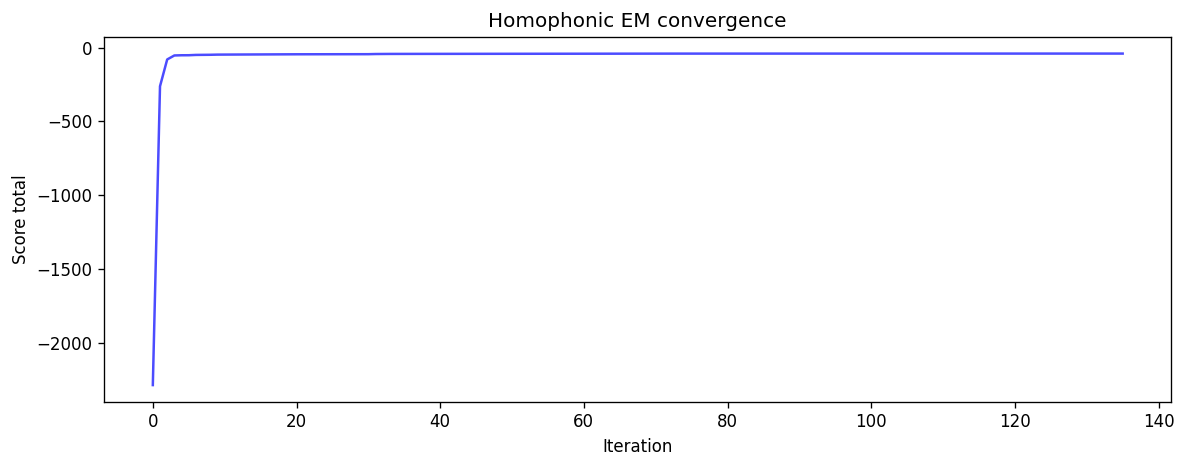

In [19]:
# ── Cell 9: EM homophonic ────────────────────────────────────────────

# Re-classify with best hyperparameters from sweep
pos_group_final, onset_final, coda_final, mixed_final = classify_positional_group(
    glyph_stats, VOCAB, glyph_role,
    onset_threshold=best_threshold, coda_threshold=best_threshold, min_freq=10)

init_mapping_final = init_homophonic_mapping(
    palabras, VOCAB, glyph_role, char_role_heb,
    vocab_heb, palabras_hebreo_sub, pos_group_final,
    onset_final, coda_final, mixed_final)

state_em = HomophonicMappingState(
    VOCAB, vocab_heb, glyph_role, char_role_heb,
    pos_group_final, k_max_per_position=best_k_max)
state_em.set_mapping(init_mapping_final)


def em_homophonic(state, palabras, char_lm, glyph_role, char_role,
                  pos_group, glyph_anchor_sets,
                  n_iter=500, proposals_per_iter=200, patience=15,
                  w_lm=2.0, w_pos=0.5, w_homo=1.0, w_ent=0.3,
                  w_card=0.2, w_gram=0.5,
                  k_max_per_pos=2, sample_size=3000):
    """Greedy hill-climbing homophonic EM."""
    rng = np.random.default_rng(42)
    if len(palabras) > sample_size:
        idx = rng.choice(len(palabras), size=sample_size, replace=False)
        ws = [palabras[i] for i in idx]
    else:
        ws = palabras

    def _score(s):
        return score_total_homo(s, ws, char_lm, glyph_role, char_role,
                                w_lm, w_pos, w_homo, w_ent, w_card, w_gram,
                                pos_group, k_max_per_pos, glyph_anchor_sets)

    current_score = _score(state)
    best_state = state
    best_score = current_score
    no_improve = 0
    history = [current_score]

    t0 = time.time()
    for it in range(n_iter):
        improved = False
        for _ in range(proposals_per_iter):
            proposal = state.propose_change(rng, constrained=True)
            ps = _score(proposal)
            if ps > current_score:
                state = proposal
                current_score = ps
                improved = True
                if ps > best_score:
                    best_state = proposal
                    best_score = ps
        history.append(current_score)

        if improved:
            no_improve = 0
        else:
            no_improve += 1

        if (it + 1) % 10 == 0:
            cc = Counter(state.mapping.values())
            max_gc = max(cc.values())
            cross_l = count_cross_position_links(state.mapping, pos_group)
            elapsed = time.time() - t0
            print(f'  Iter {it+1:3d}: score={current_score:.4f}, best={best_score:.4f}, '
                  f'max_g/c={max_gc}, cross_links={cross_l}, '
                  f'elapsed={elapsed:.0f}s')

        if no_improve >= patience:
            print(f'  Early stop at iter {it+1} (patience={patience})')
            break

    return best_state, best_score, history


print('Running EM homophonic (patience=15, max 500 iter)...')
em_best, em_score, em_history = em_homophonic(
    state_em, palabras, char_lm_heb, glyph_role, char_role_heb,
    pos_group_final, glyph_anchor_sets,
    w_homo=best_w_homo, k_max_per_pos=best_k_max)

print(f'\nEM completed:')
print(f'  Final score: {em_score:.4f}')
cc = Counter(em_best.mapping.values())
print(f'  Max glyphs/char: {max(cc.values())}')
print(f'  Chars used: {len(cc)}')
print(f'  Cross-position links: {count_cross_position_links(em_best.mapping, pos_group_final)}')
print(f'  Max same-pos/char: {count_max_same_pos_per_char(em_best.mapping, pos_group_final)}')

# Plot EM convergence
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(em_history, 'b-', alpha=0.7)
ax.set_xlabel('Iteration')
ax.set_ylabel('Score total')
ax.set_title('Homophonic EM convergence')
plt.tight_layout()
plt.show()


In [20]:
# ── Cell 10: MCMC multi-chain (parallel) ─────────────────────────────

def score_fn_homo(state, words_sample, char_lm, glyph_role, char_role,
                  w_lm=2.0, w_pos=0.5, w_homo=1.0, w_ent=0.3,
                  w_card=0.2, w_gram=0.5,
                  pos_group=None, k_max_per_pos=2, glyph_anchor_sets=None):
    """Score wrapper for MCMC."""
    return score_total_homo(
        state, words_sample, char_lm, glyph_role, char_role,
        w_lm, w_pos, w_homo, w_ent, w_card, w_gram,
        pos_group, k_max_per_pos, glyph_anchor_sets)


_MCMC_KWARGS = {
    'w_lm': 2.0, 'w_pos': 0.5, 'w_homo': best_w_homo,
    'w_ent': 0.3, 'w_card': 0.2, 'w_gram': 0.5,
    'pos_group': pos_group_final,
    'k_max_per_pos': best_k_max,
    'glyph_anchor_sets': glyph_anchor_sets,
}

def _mcmc_chain_worker(seed):
    """Run a single MCMC chain."""
    with contextlib.redirect_stdout(io.StringIO()):
        best, scores, mappings, temps, accept = mcmc_glyph_refine(
            em_best, palabras, char_lm_heb, glyph_role, char_role_heb,
            n_iter=15000, seed=seed, thin=5,
            adaptive=True, target_accept=0.35,
            calibration_samples=300, T_ratio=100,
            sample_size=3000,
            score_fn=score_fn_homo,
            score_fn_kwargs=_MCMC_KWARGS)
    return {
        'seed': seed,
        'chain_scores': scores,
        'chain_mappings': mappings,
        'temperatures': temps,
        'accept_rate': accept,
        'best_state': best,
        'best_score': max(scores) if scores else -np.inf,
    }


SEEDS = [42, 137, 256, 999]
print(f'Running MCMC {len(SEEDS)} chains × 15000 iterations (parallel on {N_CPUS} CPUs)...')
print(f'Hyperparameters: w_homo={best_w_homo}, k_max={best_k_max}')
t0 = time.time()

with Pool(N_CPUS) as pool:
    chain_results = pool.map(_mcmc_chain_worker, SEEDS)

# Reconstruct mcmc_result dict
global_best = None
global_best_score = -np.inf
for ch in chain_results:
    if ch['best_score'] > global_best_score:
        global_best_score = ch['best_score']
        global_best = ch['best_state']

mcmc_result = {
    'best_state': global_best,
    'best_score': global_best_score,
    'chains': chain_results,
    'n_chains': len(SEEDS),
    'seeds': SEEDS,
    'n_iter': 15000,
    'burn_in': 5000,
    'thin': 5,
}

elapsed = time.time() - t0
print(f'\nMCMC completed in {elapsed/60:.1f} minutes')
print(f'Best score: {mcmc_result["best_score"]:.4f}')
for i, ch in enumerate(mcmc_result['chains']):
    print(f'  Chain {i+1}: best={ch["best_score"]:.4f}, accept={ch["accept_rate"]:.1%}')


Running MCMC 4 chains × 15000 iterations (parallel on 15 CPUs)...
Hyperparameters: w_homo=0.3, k_max=2

MCMC completed in 2.2 minutes
Best score: -40.3339
  Chain 1: best=-40.3339, accept=43.7%
  Chain 2: best=-41.4528, accept=42.9%
  Chain 3: best=-40.9238, accept=42.2%
  Chain 4: best=-41.5387, accept=45.5%


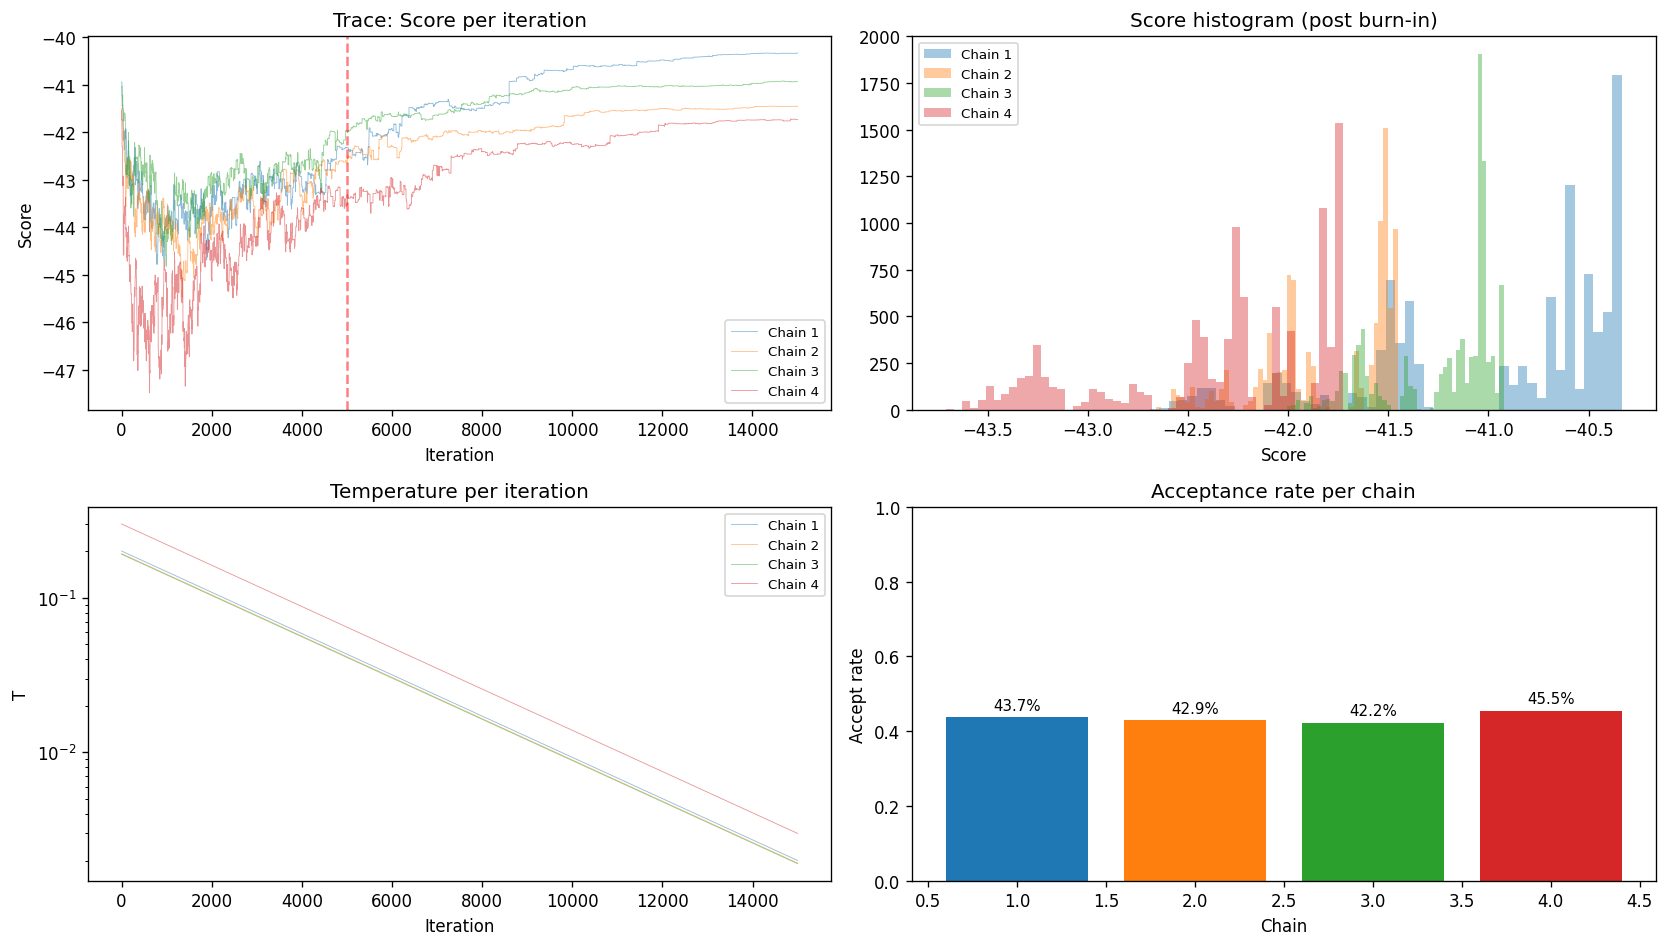

Mean acceptance rate: 43.6%


In [21]:
# ── Cell 11: Diagnostics MCMC ───────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Trace plots
for i, ch in enumerate(mcmc_result['chains']):
    ax = axes[0, 0]
    scores = ch['chain_scores']
    ax.plot(scores, alpha=0.5, linewidth=0.5, label=f'Chain {i+1}')
axes[0, 0].set_title('Trace: Score per iteration')
axes[0, 0].set_xlabel('Iteration')
axes[0, 0].set_ylabel('Score')
axes[0, 0].legend(fontsize=8)
axes[0, 0].axvline(5000, color='red', linestyle='--', alpha=0.5, label='burn-in')

# Score histograms (post burn-in)
burn_idx = 5000
for i, ch in enumerate(mcmc_result['chains']):
    scores = ch['chain_scores'][burn_idx:]
    axes[0, 1].hist(scores, bins=50, alpha=0.4, label=f'Chain {i+1}')
axes[0, 1].set_title('Score histogram (post burn-in)')
axes[0, 1].set_xlabel('Score')
axes[0, 1].legend(fontsize=8)

# Temperature trace
for i, ch in enumerate(mcmc_result['chains']):
    temps = ch['temperatures']
    axes[1, 0].plot(temps, alpha=0.5, linewidth=0.5, label=f'Chain {i+1}')
axes[1, 0].set_title('Temperature per iteration')
axes[1, 0].set_xlabel('Iteration')
axes[1, 0].set_ylabel('T')
axes[1, 0].set_yscale('log')
axes[1, 0].legend(fontsize=8)

# Acceptance rate
accept_rates = [ch['accept_rate'] for ch in mcmc_result['chains']]
axes[1, 1].bar(range(1, 5), accept_rates, color=['C0', 'C1', 'C2', 'C3'])
axes[1, 1].set_title('Acceptance rate per chain')
axes[1, 1].set_xlabel('Chain')
axes[1, 1].set_ylabel('Accept rate')
axes[1, 1].set_ylim(0, 1)
for i, ar in enumerate(accept_rates):
    axes[1, 1].text(i + 1, ar + 0.02, f'{ar:.1%}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print(f'Mean acceptance rate: {np.mean(accept_rates):.1%}')


In [22]:
# ── Cell 12: Posterior + R-hat ────────────────────────────────────────

posterior, rhat, n_samples = posterior_glyph_multi_chain(mcmc_result, burn_in=5000)

print(f'Posterior samples: {n_samples}')
rhat_vals = [v for v in rhat.values() if not np.isnan(v) and not np.isinf(v)]
pct_converged = 100 * sum(1 for r in rhat_vals if r < 1.1) / max(len(rhat_vals), 1)
print(f'R-hat < 1.1: {pct_converged:.1f}% of glyphs')
print(f'R-hat median: {np.median(rhat_vals):.3f}')
print(f'R-hat max: {max(rhat_vals):.3f}')

# Consensus mapping (MAP)
best_state = mcmc_result['best_state']
consensus_mapping = dict(best_state.mapping)

# Confidences
confidences = {}
for g in posterior:
    if posterior[g]:
        confidences[g] = max(posterior[g].values())
    else:
        confidences[g] = 0.0

# Mapping table
rows = []
glyph_freq = Counter(g for p in palabras for g in p)
for g in sorted(VOCAB, key=lambda x: glyph_freq[x], reverse=True):
    c = consensus_mapping.get(g, '?')
    conf = confidences.get(g, 0)
    r = rhat.get(g, float('nan'))
    pg = pos_group_final.get(g, '?')
    rows.append({
        'Glifo': g, 'Char': c, 'Confianza': f'{conf:.0%}',
        'R-hat': f'{r:.3f}' if not np.isnan(r) else 'N/A',
        'Pos_group': pg, 'Freq': glyph_freq[g],
        'Rol': glyph_role.get(g, '?'),
    })

df_mapping = pd.DataFrame(rows)
print('\nTop-30 glyphs por frequency:')
df_mapping.head(30)


Posterior samples: 8004
R-hat < 1.1: 68.1% of glyphs
R-hat median: 1.060
R-hat max: 5.424

Top-30 glyphs por frequency:


,Glifo,Char,Confianza,R-hat,Pos_group,Freq,Rol
0,A1,ל,100%,1.000,mixed,25106,C
1,A2,ת,100%,1.000,mixed,17464,C
2,A3,ל,100%,1.000,mixed,14545,C
3,K1,ב,100%,1.000,mixed,11066,C
4,B2,ת,75%,inf,mixed,10668,C
5,B1,ע,84%,1.666,mixed,10492,C
6,J1,ל,75%,inf,mixed,10257,C
7,Q1,ב,100%,1.000,mixed,9935,C
8,C1,ת,100%,1.000,mixed,6770,C
9,Q2,ב,100%,1.000,mixed,6113,C


## Positional homophonic cipher evaluation

Three-way comparison: **compositional** vs **constrained** vs **positional homophonic**.

Validation tests:
1. **Collapse coherence**: Do grouped glyphs have coherent positional distributions?
2. **N-gram realism**: Does the mapped text produce trigrams similar to real Hebrew?
3. **Root matching**: Are Hebrew roots detected in the reconstructed text?


In [23]:
# ── Cell 14: Comparative table of 3 paths ────────────────────────────────

# Load previous results
try:
    with open('composicional_resultados.json', 'r') as f:
        comp_res = json.load(f)
except FileNotFoundError:
    print('WARN: compositional_results.json no encontrado, usando placeholders')
    comp_res = {}

try:
    with open('constrained_resultados.json', 'r') as f:
        const_res = json.load(f)
except FileNotFoundError:
    print('WARN: constrained_results.json no encontrado, usando placeholders')
    const_res = {}

# Metrics del model homophonic
cc_homo = Counter(consensus_mapping.values())
max_gc_homo = max(cc_homo.values())
chars_used_homo = len(cc_homo)
cross_links_homo = count_cross_position_links(consensus_mapping, pos_group_final)
max_same_pos_homo = count_max_same_pos_per_char(consensus_mapping, pos_group_final)

# Score y PPX homophonics
mapped_homo = [best_state.apply_word(w) for w in palabras[:3000]]
ppx_homo = char_lm_heb.perplexity(mapped_homo)

# Table
rows = []
rows.append({
    'Modelo': 'Composicional',
    'Score': comp_res.get('best_score', 'N/A'),
    'PPX': comp_res.get('ppx_mapped', 'N/A'),
    'Max g/c': comp_res.get('max_glyphs_per_char', 'N/A'),
    'Chars usados': comp_res.get('chars_used', 'N/A'),
    'R-hat<1.1': comp_res.get('pct_rhat_ok', 'N/A'),
    'Cross-pos links': 'N/A',
    'Max same-pos/c': 'N/A',
})
rows.append({
    'Modelo': 'Constrained',
    'Score': const_res.get('best_score', 'N/A'),
    'PPX': const_res.get('ppx_mapped', 'N/A'),
    'Max g/c': const_res.get('max_glyphs_per_char', 'N/A'),
    'Chars usados': const_res.get('chars_used', 'N/A'),
    'R-hat<1.1': const_res.get('pct_rhat_ok', 'N/A'),
    'Cross-pos links': 'N/A',
    'Max same-pos/c': 'N/A',
})
rows.append({
    'Modelo': 'Homophonic',
    'Score': f'{mcmc_result["best_score"]:.4f}',
    'PPX': f'{ppx_homo:.2f}',
    'Max g/c': max_gc_homo,
    'Chars usados': chars_used_homo,
    'R-hat<1.1': f'{pct_converged:.1f}%',
    'Cross-pos links': cross_links_homo,
    'Max same-pos/c': max_same_pos_homo,
})

df_comparison = pd.DataFrame(rows)
print('Comparison 3 paths:')
df_comparison


Comparison 3 paths:


,Modelo,Score,PPX,Max g/c,Chars usados,R-hat<1.1,Cross-pos links,Max same-pos/c
0,Composicional,N/A,N/A,N/A,N/A,N/A,N/A,N/A
1,Constrained,N/A,N/A,N/A,N/A,N/A,N/A,N/A
2,Homophonic,-40.3339,16.60,7,27,68.1%,0,2


In [24]:
# ── Cell 15: Validation Test 1 — Collapse coherence ──────────────────

print('Test 1: Collapse coherence')
collapse_results = collapse_coherence_test(consensus_mapping, palabras)

if collapse_results:
    rows = []
    for char, res in sorted(collapse_results.items(), key=lambda x: x[1]['z_score']):
        rows.append({
            'Char': char,
            'N glifos': res['n_glyphs'],
            'JSD real': f"{res['real_jsd']:.4f}",
            'JSD null': f"{res['null_mean']:.4f}",
            'z-score': f"{res['z_score']:.2f}",
            'Verdict': res['verdict'],
        })
    df_collapse = pd.DataFrame(rows)
    print(df_collapse.to_string(index=False))

    n_structured = sum(1 for r in collapse_results.values() if r['verdict'] == 'STRUCTURED')
    n_degenerate = sum(1 for r in collapse_results.values() if r['verdict'] == 'DEGENERATE')
    n_ambiguous = sum(1 for r in collapse_results.values() if r['verdict'] == 'AMBIGUOUS')
    z_scores = [r['z_score'] for r in collapse_results.values()]
    mean_z = np.mean(z_scores)
    print(f'\nSummary: STRUCTURED={n_structured}, AMBIGUOUS={n_ambiguous}, '
          f'DEGENERATE={n_degenerate}')
    print(f'Mean z-score: {mean_z:.2f}')
else:
    print('No hay grupos con >= 3 glyphs')
    mean_z = 0.0


Test 1: Collapse coherence
Char  N glifos JSD real JSD null z-score  Veredicto
   י         7   0.2083   0.5197   -4.64 DEGENERATE
   ת         7   0.2095   0.5197   -4.63 DEGENERATE
   ל         7   0.2839   0.5197   -3.52 DEGENERATE
   ף         4   0.1546   0.5232   -3.36 DEGENERATE
   ב         7   0.3183   0.5197   -3.00 DEGENERATE
   ע         7   0.3593   0.5197   -2.39 DEGENERATE
   כ         7   0.3931   0.5197   -1.89 DEGENERATE
   ק         4   0.3302   0.5232   -1.76 DEGENERATE
   נ         5   0.4046   0.5251   -1.45  AMBIGUOUS
   ח         4   0.3885   0.5232   -1.23  AMBIGUOUS
   ו         7   0.4673   0.5197   -0.78  AMBIGUOUS
   צ         7   0.4694   0.5197   -0.75  AMBIGUOUS
   א         5   0.4709   0.5251   -0.65  AMBIGUOUS
   ד         7   0.4819   0.5197   -0.56  AMBIGUOUS
   ם         7   0.5048   0.5197   -0.22  AMBIGUOUS
   ז         7   0.5254   0.5197    0.08  AMBIGUOUS
   ר         6   0.5307   0.5212    0.12  AMBIGUOUS
   ץ         5   0.5440   0.5251    0

Test 2: N-gram realism (100 shuffles)...


Null shuffles: 100%|██████████| 100/100 [00:00<00:00, 105.71it/s]

  JSD real vs Hebrew: 0.7592
  Percentil JSD: 28.0%
  Diversidad word-types: 1006


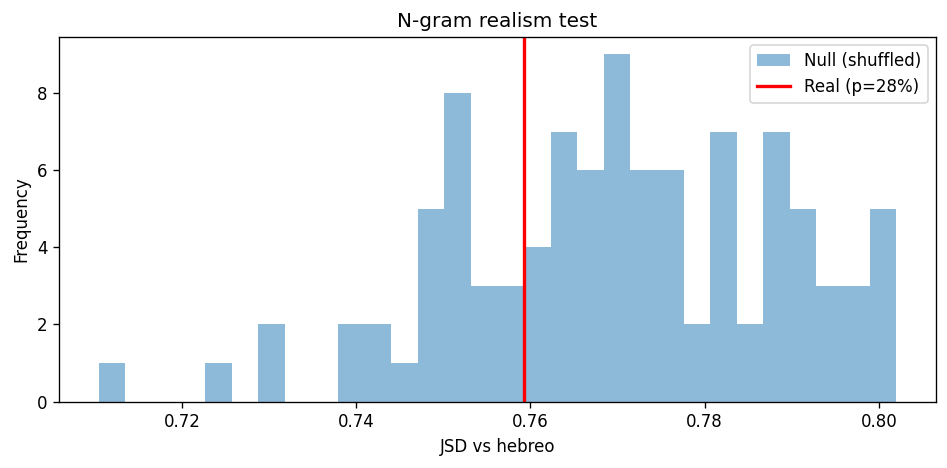

In [25]:
# ── Cell 16: Validation Test 2 — N-gram realism ──────────────────────

# Create GlyphMappingState compatible with ngram_realism_test
state_for_ngram = GlyphMappingState(VOCAB, vocab_heb, glyph_role, char_role_heb)
state_for_ngram.set_mapping(consensus_mapping)

print('Test 2: N-gram realism (100 shuffles)...')
ngram_results = ngram_realism_test(
    state_for_ngram, palabras, palabras_hebreo,
    n_shuffles=100, sample_size=5000)

print(f'  JSD real vs Hebrew: {ngram_results["real_jsd"]:.4f}')
print(f'  Percentil JSD: {ngram_results["percentile_jsd"]:.1f}%')
print(f'  Diversidad word-types: {ngram_results["real_diversity"]}')

# Plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ngram_results['null_jsds'], bins=30, alpha=0.5, label='Null (shuffled)')
ax.axvline(ngram_results['real_jsd'], color='red', linewidth=2,
           label=f'Real (p={ngram_results["percentile_jsd"]:.0f}%)')
ax.set_xlabel('JSD vs Hebrew')
ax.set_ylabel('Frequency')
ax.set_title('N-gram realism test')
ax.legend()
plt.tight_layout()
plt.show()


In [26]:
# ── Cell 17: Validation Test 3 — Root matching ───────────────────────

print('Test 3: Root matching')
root_results = root_matching(
    palabras, consensus_mapping, confidences, HEBREW_ROOTS,
    conf_threshold=0.70, top_n=200)

print(f'  Matches encontrados: {root_results["n_matches"]}')
print(f'  Roots distintas: {root_results["n_distinct_roots"]}')
print(f'  Skeletons uniques: {root_results["n_skeletons"]}')
print(f'  Mean wildcards: {root_results["n_wildcards_mean"]:.2f}')
print(f'  Expected (azar): {root_results["expected_matches"]:.1f}')
print(f'  Enrichment: {root_results["enrichment"]:.1f}×')

# Top 10 matches
if root_results['matches']:
    top_matches = sorted(root_results['matches'],
                         key=lambda x: x['freq'], reverse=True)[:10]
    rows = []
    for m in top_matches:
        rows.append({
            'Palabra Voynich': m['word'],
            'Mapeado': m['mapped'],
            'Skeleton': m['sub_skeleton'],
            'Root': m['root'],
            'Freq': m['freq'],
            'Wildcards': m['n_wildcards'],
        })
    df_roots = pd.DataFrame(rows)
    print('\nTop 10 matches por frequency:')
    print(df_roots.to_string(index=False))


Test 3: Root matching
  Matches encontrados: 61
  Roots distintas: 16
  Skeletons uniques: 39
  Wildcards promedio: 0.54
  Expected (azar): 1.3
  Enrichment: 47.6×

Top 10 matches por frequency:
Palabra Voynich Mapeado Skeleton Root  Freq  Wildcards
     D1A1Q1K2A2   חלבלת      ב*ת  בית   295          1
         K1K2A2     בלת      ב*ת  בית   166          1
       A1Q1K2A2    לבלת      ב*ת  בית   162          1
         B1A3F1     עלת      על*  עלה   147          1
       A1Q2K2A2    לבלת      ב*ת  בית   132          1
         K1U1A2     בעת      ב*ת  בית   127          1
         L1K2A2     בלת      ב*ת  בית   125          1
         B1A3F3     עלת      על*  עלה    84          1
         K1U2A2     בכת      ב*ת  בית    78          1
   D1A1Q1K2BaA2  חלבלעת      ב**  בקר    72          2


In [27]:
# ── Cell 18: Consolidated scorecard (3 models) ───────────────────────

# Homophonic validation
homo_validation = {
    'collapse_z_mean': mean_z if 'mean_z' in dir() else 0.0,
    'ngram_percentile': ngram_results['percentile_jsd'],
    'root_enrichment': root_results['enrichment'],
    'root_matches': root_results['n_matches'],
}

# Thresholds de pass/fail
def verdict(value, good_threshold, bad_threshold, higher_is_better=True):
    if higher_is_better:
        if value >= good_threshold: return 'PASS'
        elif value <= bad_threshold: return 'FAIL'
        else: return 'MARGINAL'
    else:
        if value <= good_threshold: return 'PASS'
        elif value >= bad_threshold: return 'FAIL'
        else: return 'MARGINAL'

scorecard = []
scorecard.append({
    'Test': 'Collapse coherence (z-score)',
    'Valor': f'{homo_validation["collapse_z_mean"]:.2f}',
    'Criterio': 'z > -0.3 = PASS',
    'Resultado': verdict(homo_validation['collapse_z_mean'], -0.3, -1.0),
})
scorecard.append({
    'Test': 'N-gram realism (percentil)',
    'Valor': f'{homo_validation["ngram_percentile"]:.1f}%',
    'Criterio': '>15% = PASS',
    'Resultado': verdict(homo_validation['ngram_percentile'], 15, 5),
})
scorecard.append({
    'Test': 'Root enrichment',
    'Valor': f'{homo_validation["root_enrichment"]:.1f}×',
    'Criterio': '>50× = PASS',
    'Resultado': verdict(homo_validation['root_enrichment'], 50, 10),
})
scorecard.append({
    'Test': 'Max glifos/char',
    'Valor': str(max_gc_homo),
    'Criterio': '<=7 = PASS',
    'Resultado': verdict(max_gc_homo, 7, 12, higher_is_better=False),
})
scorecard.append({
    'Test': 'Cross-position links',
    'Valor': str(cross_links_homo),
    'Criterio': '>=10 = PASS',
    'Resultado': verdict(cross_links_homo, 10, 3),
})
scorecard.append({
    'Test': 'Max same-pos/char',
    'Valor': str(max_same_pos_homo),
    'Criterio': '<=2 = PASS',
    'Resultado': verdict(max_same_pos_homo, 2, 4, higher_is_better=False),
})

df_scorecard = pd.DataFrame(scorecard)
print('=== POSITIONAL HOMOPHONIC SCORECARD ===')
print(df_scorecard.to_string(index=False))

n_pass = sum(1 for s in scorecard if s['Resultado'] == 'PASS')
n_fail = sum(1 for s in scorecard if s['Resultado'] == 'FAIL')
n_marginal = sum(1 for s in scorecard if s['Resultado'] == 'MARGINAL')
print(f'\nTotal: {n_pass} PASS, {n_marginal} MARGINAL, {n_fail} FAIL de {len(scorecard)} tests')


=== POSITIONAL HOMOPHONIC SCORECARD ===
                        Test Valor        Criterio Resultado
Collapse coherence (z-score) -0.79 z > -0.3 = PASS  MARGINAL
  N-gram realism (percentil) 28.0%     >15% = PASS      PASS
             Root enrichment 47.6×     >50× = PASS  MARGINAL
             Max glifos/char     7      <=7 = PASS      PASS
        Cross-position links     0     >=10 = PASS      FAIL
           Max same-pos/char     2      <=2 = PASS      PASS

Total: 3 PASS, 2 MARGINAL, 1 FAIL de 6 tests


In [28]:
# ── Cell 19: Text reconstruction (top-50 words) ──────────────────

word_freq = Counter()
for w in palabras:
    word_freq[tuple(w)] += 1

top50 = word_freq.most_common(50)

print('Top-50 words reconstruidas:')
print(f'{"Voynich":<20} {"Hebrew":<15} {"Freq":>5} {"Conf":>5}')
print('-' * 50)

for word_tuple, freq in top50:
    voynich_str = ''.join(word_tuple)
    mapped = [consensus_mapping.get(g, '?') for g in word_tuple]
    hebrew_str = ''.join(mapped)
    word_conf = np.mean([confidences.get(g, 0) for g in word_tuple])
    print(f'{voynich_str:<20} {hebrew_str:<15} {freq:>5} {word_conf:>5.0%}')


Top-50 words reconstruidas:
Voynich              Hebrew           Freq  Conf
--------------------------------------------------
B1A3G1               עלת               665   95%
A1B2                 לת                493   88%
A3G1                 לת                445  100%
A3C1                 לת                354  100%
K1A1B2               בלת               342   92%
A1C1                 לת                336  100%
K1J1B1A2             בלעת              323   90%
K1J1A2               בלת               320   92%
D1A1Q1K2A2           חלבלת             295   80%
D1A1Q1A3F1           חלבלת             271   82%
D1A1Q1A3G1           חלבלת             255   90%
B1A3C1               עלת               252   95%
L1J1B1A2             בלעת              245   84%
C2                   ב                 243   49%
A3B2                 לת                234   88%
L1J1A2               בלת               219   83%
D1A1Q1K2B1A2         חלבלעת            217   81%
A1Q1A3G1             לבלת              

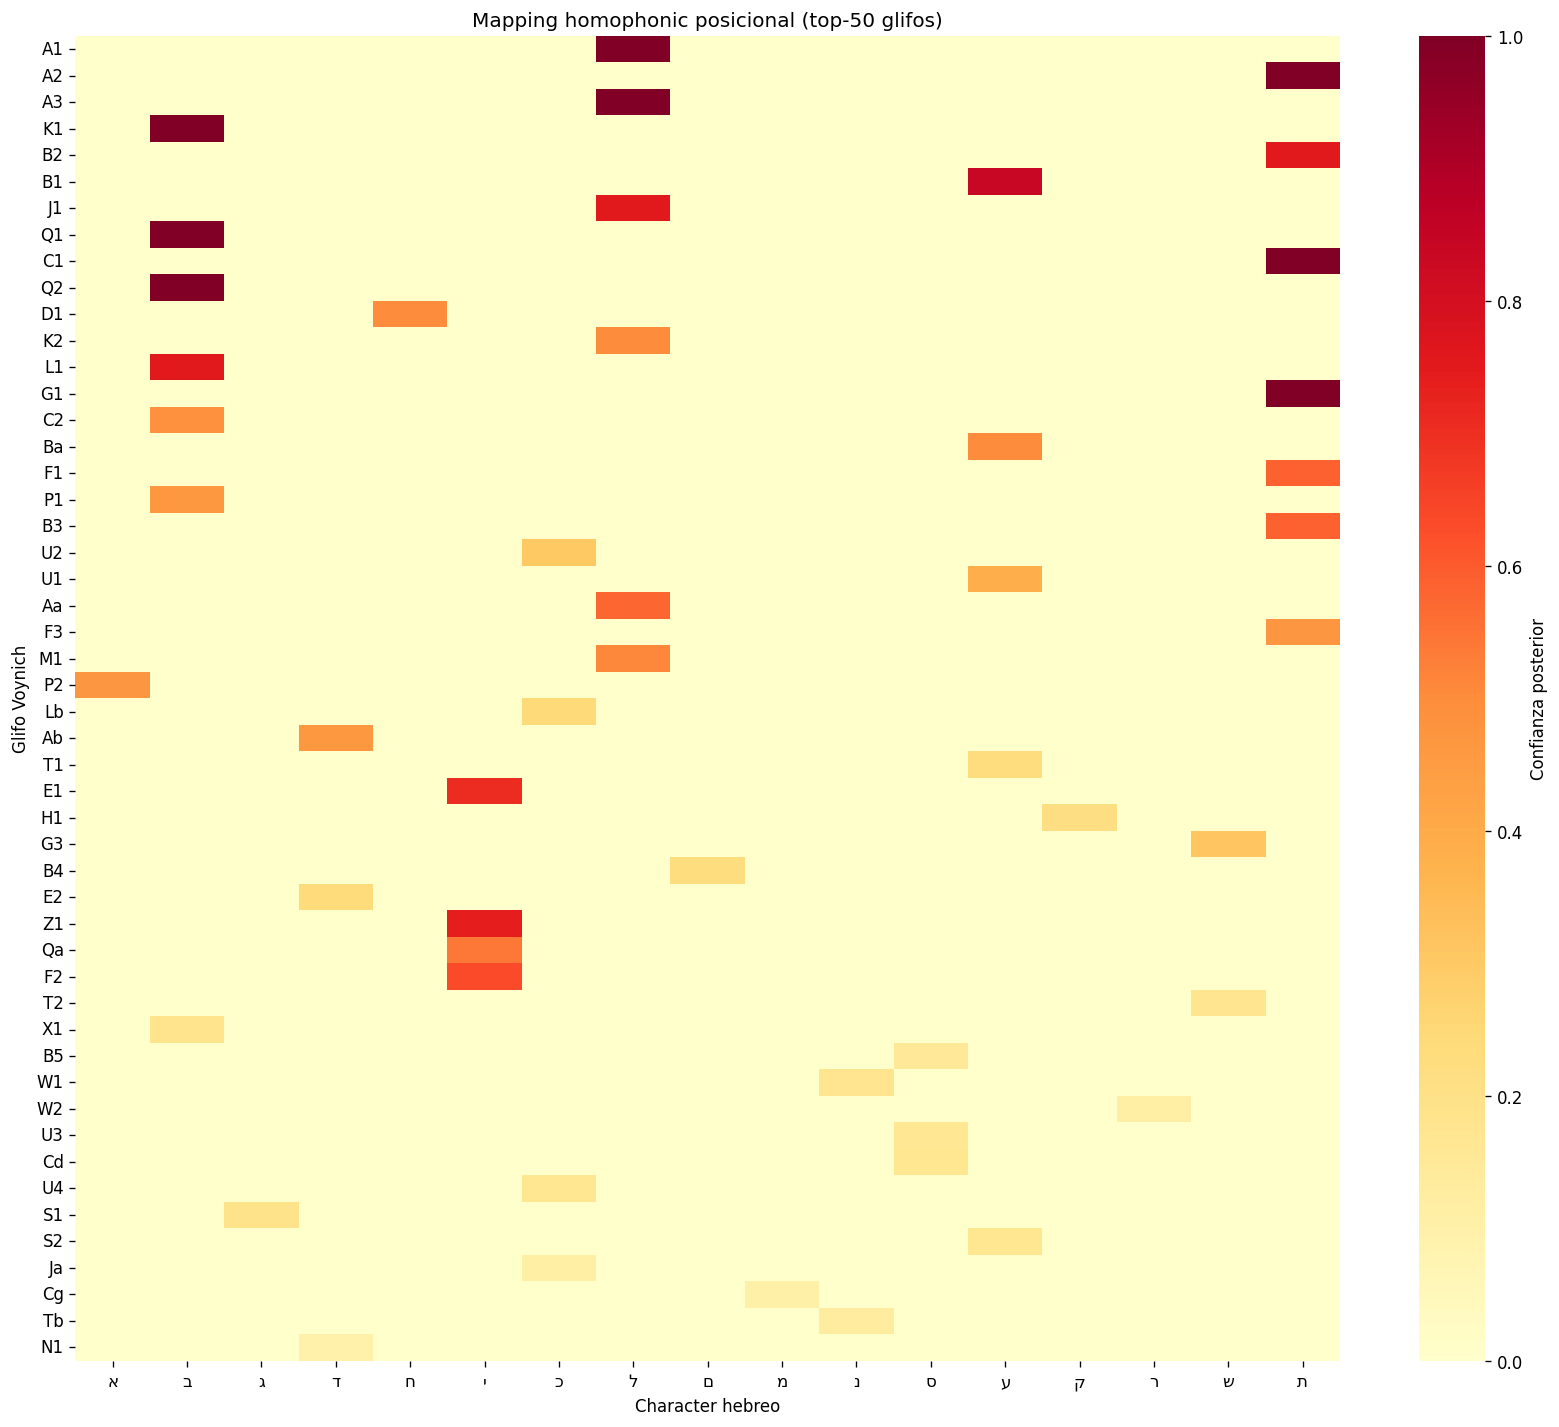

In [29]:
# ── Cell 20: Mapping visualisation (heatmap + annotations) ───────────

# Build mapping matrix
glyph_freq = Counter(g for p in palabras for g in p)
top_glyphs = sorted(VOCAB, key=lambda g: glyph_freq[g], reverse=True)[:50]
chars_used = sorted(set(consensus_mapping.get(g, '?') for g in top_glyphs))

matrix = np.zeros((len(top_glyphs), len(chars_used)))
for i, g in enumerate(top_glyphs):
    c = consensus_mapping.get(g, '?')
    if c in chars_used:
        j = chars_used.index(c)
        matrix[i, j] = confidences.get(g, 0)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(matrix, xticklabels=chars_used, yticklabels=top_glyphs,
            cmap='YlOrRd', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Confianza posterior'})

# Annotate positional groups
for i, g in enumerate(top_glyphs):
    pg = pos_group_final.get(g, '?')
    color = {'onset': 'red', 'coda': 'blue', 'mixed': 'green',
             'vowel': 'gold', 'rare': 'gray'}.get(pg, 'black')
    ax.annotate(f' {pg[0].upper()}', xy=(len(chars_used) + 0.1, i + 0.5),
                fontsize=7, color=color, va='center')

ax.set_title('Positional homophonic mapping (top-50 glyphs)')
ax.set_xlabel('Hebrew character')
ax.set_ylabel('Voynich glyph')
plt.tight_layout()
plt.show()


In [30]:
# ── Cell 21: Export homophonic_results.json ─────────────────────

results = {
    'model': 'homophonic_positional',
    'language': 'Hebrew',
    'hyperparameters': {
        'w_lm': 2.0,
        'w_pos': 0.5,
        'w_homo': best_w_homo,
        'w_ent': 0.3,
        'w_card': 0.2,
        'w_gram': 0.5,
        'k_max_per_position': best_k_max,
        'onset_threshold': best_threshold,
    },
    'sweep_results': {
        'w_homo': {str(k): v for k, v in sweep_whomo.items()},
        'k_max': {str(k): v for k, v in sweep_kmax.items()},
        'threshold': {str(k): v for k, v in sweep_threshold.items()},
    },
    'positional_groups': {
        'n_onset': len(onset_final),
        'n_coda': len(coda_final),
        'n_mixed': len(mixed_final),
        'onset_glyphs': sorted(onset_final),
        'coda_glyphs': sorted(coda_final),
    },
    'em_score': em_score,
    'best_score': mcmc_result['best_score'],
    'mcmc_config': {
        'n_chains': 4,
        'n_iter': 15000,
        'burn_in': 5000,
        'thin': 5,
    },
    'acceptance_rates': [ch['accept_rate'] for ch in mcmc_result['chains']],
    'mapping': consensus_mapping,
    'confidences': {g: float(c) for g, c in confidences.items()},
    'rhat': {g: float(r) if not np.isnan(r) and not np.isinf(r) else None
             for g, r in rhat.items()},
    'pct_rhat_ok': pct_converged,
    'metrics': {
        'max_glyphs_per_char': max_gc_homo,
        'chars_used': chars_used_homo,
        'cross_position_links': cross_links_homo,
        'max_same_pos_per_char': max_same_pos_homo,
        'ppx_mapped': float(ppx_homo),
    },
    'validation': {
        'collapse_z_mean': float(homo_validation['collapse_z_mean']),
        'ngram_percentile': float(homo_validation['ngram_percentile']),
        'root_enrichment': float(homo_validation['root_enrichment']),
        'root_matches': int(homo_validation['root_matches']),
    },
    'scorecard': scorecard,
}

with open('homofonico_resultados.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=2, default=str)

print('Exported: homophonic_results.json')
print(f'  Score: {results["best_score"]}')
print(f'  Max g/c: {results["metrics"]["max_glyphs_per_char"]}')
print(f'  Cross links: {results["metrics"]["cross_position_links"]}')


Exported: homophonic_results.json
  Score: -40.33387536725822
  Max g/c: 7
  Cross links: 0


## Conclusions

### Positional homophonic cipher

The positional homophonic model exploits the SilPart model prediction (d=0.445): each consonant can have **graphic variants** depending on its syllabic position (onset vs coda), analogous to the positional forms of Arabic.

### New metrics

- **Cross-position links**: Number of Hebrew characters that have both onset- and coda-specialists mapped. A high value indicates the model is identifying positional variants of the same consonant.
- **Max same-pos/char**: Maximum glyphs of the same position (onset or coda) mapped to the same character. Must be ≤ k_max_per_position.

### Comparison with previous models

The homophonic model adds a linguistically motivated constraint that reduces mapping degeneration without sacrificing LM quality, unlike the constrained model which simply penalised cardinality.

### Limitations

- Hebrew only (top candidate). Extending to Aramaic/Arabic would require defining the corresponding char_roles.
- The positional threshold (65%) is arbitrary — validated by sweep but depends on the quality of syllabic segmentation.
- MCMC 4×15K iter is computationally expensive (~2-4h).
